# 139 · Latent analogies (decres-rescale-aug10-v1)
Four parameter-free analogies in the 512-d latent; nothing is learned, only averages. Each is searched over box × speaker × objects; the top 3 configurations (by honest top-1 retrieval) get one figure each (12 figures, also saved as PDF in `notebooks/out/139_*.pdf`).
1. **pair**: ½(X + Y) + c = X+Y pair, c = mean pair − ½(mean X + mean Y) (mean interaction, leave-one-out)
2. **object swap**: X at p − mean X + mean Y = Y at p
3. **box swap**: X at p in box A − mean box A + mean box B = X at p in box B
4. **composition** (strict): mean X in box A − mean A + mean at p in B = X at p in B, i.e. mean(X in A) + [mean B − mean A] + [mean at p in B − mean B]; never uses X recorded in B (box B averages use its other objects only)

Retrieval (word2vec-style): cosine of the prediction against every candidate, both centred on the candidates' mean; hit = the most similar candidate is a true one (same position = within `R_PX` px of p, mask CoM, 64×64 frame). Honest scores use the nearest single recordings; the plotted example of each configuration is cherry-picked (largest margin = cos(true) − cos(best wrong)). Figure: 2-D PCA of the configuration's latents applied *linearly* (no centring), so tip-to-tail sums are exact sums; cosine ranking; the analogy as a picture equation.

4b. **simple composition**: mean X in box + (mean at p − mean) = X at p in box; the position shift comes from the box's other objects (uses X-in-box data, leave-one-out).

Every term is a plain group average (no overall mean): each analogy = one average + differences of two averages.

In [1]:
RUN = "decres-rescale-aug10-v1"
K, R_PX, TOP = 5, 2.0, 3   # singles searched per object (pair analogy) · "same position" radius (px) · configurations plotted per analogy
BAD = "shifted|unseen-speaker|lid"  # splits whose latents are not comparable
OBJS = ["red-cube", "soap dispenser", "candle", "vase"]
PAIRS = {"red-cube+vase": [("red-cube", "red-cube0"), ("vase", "vase0")], "green-cube+red-cube": [("red-cube", "green-cube0"), ("red-cube", "red-cube0")]}
ICON = {"red-cube": "cube", "vase": "vase", "candle": "candle", "soap dispenser": "soap", "red-cube+vase": "cube_and_vase", "green-cube+red-cube": "two_cubes"}

In [2]:
import sys, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(); sys.path.insert(0, str(ROOT / "src9"))
from dataset import load_splits
C = ROOT / "runs/_src9_cache/nb137" / RUN  # latent + metadata cached by nb137
df, Z = pd.read_csv(C / "meta.csv", dtype={"speaker": str}), np.load(C / "feats.npz")["latent"]
dirs = list(load_splits()[0].keys()); df["dir"] = [dirs[i] for i in np.load(ROOT / "runs/_src9_cache/nb136/base.npz")["i"]]  # row ↔ sample dir (verified)
df = df[~df.split.str.contains(BAD)]
ID = lambda j: Path(df.loc[j, "dir"]).name
def com(f): m = np.load(f) > 0; r, c = np.nonzero(m); return (c.mean() + .5) * 64 / m.shape[1] - .5, (r.mean() + .5) * 64 / m.shape[0] - .5  # instance-mask CoM, 64×64 frame
for pair, parts in PAIRS.items():  # per-object positions inside the two-object samples
    ix = df.index[df.object == pair]
    for j, (_, inst) in enumerate(parts): df.loc[ix, [f"{pair}_x{j}", f"{pair}_y{j}"]] = [com(Path(d) / f"image/smasks/{inst}.npy") for d in df.dir[ix]]
EMPTY = {b: df.index[(df.object == "empty") & (df.box == b)][0] for b in df.box.unique()}  # one empty-box sample per box (its photo = "the box")
unit = lambda X: X / np.linalg.norm(X, axis=-1, keepdims=True)
print(len(df), "samples", df.box.value_counts().to_dict())

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

15132 samples {'cardboard': 6687, 'plastic': 5066, 'gastro': 3379}


In [3]:
# 1) pair: ½(X + Y) + c = pair
R1, EX1 = [], {}
for pair, parts in PAIRS.items():
    for (box, spk), p in df[df.object == pair].groupby(["box", "speaker"]):
        S = df[(df.box == box) & (df.speaker == spk)]; Y = Z[p.index]; n = len(p); mo = [Z[S.index[S.object == ob]].mean(0) for ob, _ in parts]
        NB = [[np.hypot(S[S.object == ob].x - r[f"{pair}_x{j}"], S[S.object == ob].y - r[f"{pair}_y{j}"]).nsmallest(K).index for _, r in p.iterrows()] for j, (ob, _) in enumerate(parts)]
        hits, best = [], None
        for i in range(n):
            m = (Y.sum(0) - Y[i]) / (n - 1); c = m - .5 * (mo[0] + mo[1]); Yc = unit(Y - m)
            for u, v in itertools.product(NB[0][i], NB[1][i]):
                cs = Yc @ unit(.5 * (Z[u] + Z[v]) + c - m); mg = cs[i] - np.delete(cs, i).max()
                if u == NB[0][i][0] and v == NB[1][i][0]: hits.append(mg > 0)
                if best is None or mg > best[0]: best = (mg, i, u, v, cs, c)
        mg, i, u, v, cs, c = best; tm = np.arange(n) == i
        R1.append(dict(pair=pair, box=box, speaker=spk, n=n, top1=np.mean(hits), chance=1 / n))
        EX1[(pair, box, spk)] = dict(steps=[(.5 * Z[u], "½·" + parts[0][0], "tab:red"), (.5 * Z[v], "+ ½·" + parts[1][0], "tab:blue"), (c, "+ c (mean interaction)", "tab:purple")],
            real=(Y[i], f"real {pair} (sample {ID(p.index[i])})"), Q=Z[np.r_[p.index, S.index[S.object.isin([ob for ob, _ in parts])]]], cs=cs, tm=tm, icon=pair,
            eq=[("text", "½ ×"), ("text", "("), ("photo", u, parts[0][0]), ("text", "+"), ("photo", v, parts[1][0]), ("text", ")"), ("text", "+"), ("text", "c"), ("text", "="), ("photo", p.index[i], f"real {pair}")],
            title=f"pair · {pair} · {box} · speaker {spk}: ½(X + Y) + c = pair", what=f"which real {pair} is closest? ({n} pairs)")
T1 = pd.DataFrame(R1).sort_values("top1", ascending=False); T1.round(3)

,pair,box,speaker,n,top1,chance
8,red-cube+vase,plastic,3,35,0.971,0.029
9,red-cube+vase,plastic,5,35,0.971,0.029
10,red-cube+vase,plastic,7,35,0.971,0.029
7,red-cube+vase,plastic,1,35,0.943,0.029
4,red-cube+vase,gastro,1,42,0.786,0.024
6,red-cube+vase,gastro,7,42,0.762,0.024
18,green-cube+red-cube,plastic,1,80,0.750,0.012
19,green-cube+red-cube,plastic,3,80,0.725,0.012
21,green-cube+red-cube,plastic,7,80,0.712,0.012
20,green-cube+red-cube,plastic,5,80,0.700,0.012


In [4]:
# 2) object swap: X at p − mean X + mean Y = Y at p
def swap_search(xs, ys, base, mY_c, near_xy):  # generic: prediction for each x = Z[x] + base; candidates ys centred on mY_c; true = ys within R_PX of x's position
    Yc = unit(Z[ys.index] - mY_c); hits, chance, best = [], [], None
    for j, r in xs.iterrows():
        d = np.hypot(ys.x.values - r.x, ys.y.values - r.y); ok = d <= R_PX
        if not ok.any() or ok.all(): continue
        cs = Yc @ unit(Z[j] + base(j) - mY_c); mg = cs[ok].max() - cs[~ok].max(); hits.append(mg > 0); chance.append(ok.mean())
        if best is None or mg > best[0]: best = (mg, j, ys.index[ok][np.argmax(cs[ok])], cs, ok)
    return hits, chance, best
R2, EX2 = [], {}
for (box, spk), S in df.groupby(["box", "speaker"]):
    for X, Yo in itertools.permutations(OBJS, 2):
        xs, ys = S[S.object == X], S[S.object == Yo]
        if len(xs) < 30 or len(ys) < 30: continue
        mX, mY = Z[xs.index].mean(0), Z[ys.index].mean(0)
        hits, chance, (mg, j, jt, cs, ok) = swap_search(xs, ys, lambda j: mY - mX, mY, None)
        R2.append(dict(box=box, speaker=spk, X=X, Y=Yo, n=len(hits), top1=np.mean(hits), chance=np.mean(chance)))
        EX2[(box, spk, X, Yo)] = dict(steps=[(Z[j], f"{X} at p (sample {ID(j)})", "tab:red"), (-mX, f"− mean {X}", "0.45"), (mY, f"+ mean {Yo}", "tab:orange")],
            real=(Z[jt], f"real {Yo} at p (sample {ID(jt)})"), Q=Z[np.r_[xs.index, ys.index]], cs=cs, tm=ok, icon=Yo,
            eq=[("photo", j, f"{X} at p"), ("text", "−"), ("icon", X, f"mean {X}"), ("text", "+"), ("icon", Yo, f"mean {Yo}"), ("text", "="), ("photo", jt, f"{Yo} at p")],
            title=f"object swap · {box} · speaker {spk}: {X} at p − mean {X} + mean {Yo} = {Yo} at p", what=f"which {Yo} is closest? (green = within {R_PX:.0f} px of p)")
T2 = pd.DataFrame(R2).sort_values("top1", ascending=False); T2.head(10).round(3)

,box,speaker,X,Y,n,top1,chance
122,plastic,7,red-cube,vase,202,0.782,0.011
98,plastic,3,red-cube,vase,202,0.762,0.011
86,plastic,1,red-cube,vase,199,0.754,0.011
110,plastic,5,red-cube,vase,202,0.718,0.011
129,plastic,7,vase,red-cube,189,0.683,0.009
125,plastic,7,soap dispenser,vase,253,0.660,0.011
93,plastic,1,vase,red-cube,188,0.654,0.009
89,plastic,1,soap dispenser,vase,254,0.654,0.010
82,gastro,7,vase,soap dispenser,165,0.630,0.008
101,plastic,3,soap dispenser,vase,253,0.625,0.011


In [5]:
# 3) box swap: X at p in box A − mean box A + mean box B = X at p in box B   (same speaker; "same position" in the 64×64 mask frame of each box)
R3, EX3 = [], {}
for spk, S in df.groupby("speaker"):
    for X in OBJS:
        for A, B in itertools.permutations(sorted(S.box.unique()), 2):
            xs, ys = S[(S.object == X) & (S.box == A)], S[(S.object == X) & (S.box == B)]
            if len(xs) < 30 or len(ys) < 30: continue
            mA, mB, mYc = Z[S.index[S.box == A]].mean(0), Z[S.index[S.box == B]].mean(0), Z[ys.index].mean(0)
            hits, chance, (mg, j, jt, cs, ok) = swap_search(xs, ys, lambda j: mB - mA, mYc, None)
            R3.append(dict(speaker=spk, object=X, A=A, B=B, n=len(hits), top1=np.mean(hits), chance=np.mean(chance)))
            EX3[(spk, X, A, B)] = dict(steps=[(Z[j], f"{X} at p in {A} (sample {ID(j)})", "tab:red"), (-mA, f"− mean {A}", "0.45"), (mB, f"+ mean {B}", "tab:orange")],
                real=(Z[jt], f"real {X} at p in {B} (sample {ID(jt)})"), Q=Z[np.r_[xs.index, ys.index]], cs=cs, tm=ok, icon=X,
                eq=[("photo", j, f"{X} at p in {A}"), ("text", "−"), ("box", A, f"mean {A}"), ("text", "+"), ("box", B, f"mean {B}"), ("text", "="), ("photo", jt, f"{X} at p in {B}")],
                title=f"box swap · speaker {spk} · {X}: at p in {A} − mean {A} + mean {B} = at p in {B}", what=f"which {X} in {B} is closest? (green = within {R_PX:.0f} px)")
T3 = pd.DataFrame(R3).sort_values("top1", ascending=False); T3.head(10).round(3)

,speaker,object,A,B,n,top1,chance
39,3,candle,gastro,plastic,210,0.119,0.011
44,3,vase,gastro,cardboard,181,0.110,0.009
73,7,candle,plastic,gastro,245,0.110,0.009
54,5,vase,cardboard,plastic,114,0.096,0.011
45,3,vase,gastro,plastic,157,0.089,0.010
71,7,candle,gastro,plastic,211,0.081,0.011
79,7,vase,plastic,gastro,177,0.079,0.008
59,7,red-cube,gastro,plastic,191,0.079,0.009
29,3,red-cube,plastic,gastro,228,0.075,0.008
18,1,vase,cardboard,gastro,185,0.070,0.009


In [6]:
# 4) composition (strict, group averages only): X at p in box B ≈ mean(X in box A) + [mean B − mean A] + [mean at p in B − mean B]
#    = mean(X in A) − mean A + mean at p in B. Never uses X recorded in B: box B's averages use only its OTHER objects.
R4, EX4 = [], {}
for spk, S in df.groupby("speaker"):
    for X in OBJS:
        for A, B in itertools.permutations(sorted(S.box.unique()), 2):
            tg, src_ = S[(S.object == X) & (S.box == B)], S[(S.object == X) & (S.box == A)]
            restB = S[(S.box == B) & (S.object != X)]
            if len(tg) < 30 or len(src_) < 30: continue
            mXA, mA, mB = Z[src_.index].mean(0), Z[S.index[S.box == A]].mean(0), Z[restB.index].mean(0)
            Yc = unit(Z[tg.index] - Z[tg.index].mean(0)); hits, chance, best = [], [], None
            for j, r in tg.iterrows():
                d = np.hypot(tg.x.values - r.x, tg.y.values - r.y); ok = d <= R_PX
                nb_ = restB.index[np.hypot(restB.x - r.x, restB.y - r.y) <= R_PX]
                if ok.all() or len(nb_) < 3: continue
                mPos = Z[nb_].mean(0); cs = Yc @ unit(mXA - mA + mPos - Z[tg.index].mean(0))
                mg = cs[ok].max() - cs[~ok].max(); hits.append(mg > 0); chance.append(ok.mean())
                if best is None or mg > best[0]: best = (mg, j, tg.index[ok][np.argmax(cs[ok])], cs, ok, mPos, r.x, r.y, len(nb_))
            if not hits: continue
            mg, j, jt, cs, ok, mPos, px, py, nnb = best
            R4.append(dict(speaker=spk, object=X, A=A, B=B, n=len(hits), top1=np.mean(hits), chance=np.mean(chance)))
            EX4[(spk, X, A, B)] = dict(steps=[(mXA, f"mean {X} in {A}", "tab:red"), (mB - mA, f"+ mean {B} − mean {A}", "tab:orange"), (mPos - mB, f"+ mean at p in {B} − mean {B} ({nnb} other-object samples)", "tab:blue")],
                real=(Z[jt], f"real {X} at p in {B} (sample {ID(jt)})"), Q=Z[S.index[S.box.isin([A, B])]], cs=cs, tm=ok, icon=X,
                eq=[("icon", X, f"mean {X} in {A}"), ("text", "−"), ("box", A, f"mean {A}"), ("text", "+"), ("box", B, f"mean at p in {B}", (px, py)), ("text", "="), ("photo", jt, f"{X} at p in {B}")],
                title=f"composition · speaker {spk}: mean {X} in {A} − mean {A} + mean at p in {B} = {X} at p in {B}", what=f"which {X} in {B} is closest? (green = within {R_PX:.0f} px)")
T4 = pd.DataFrame(R4).sort_values("top1", ascending=False); T4.head(10).round(3)

,speaker,object,A,B,n,top1,chance
59,7,red-cube,gastro,plastic,238,0.718,0.011
57,7,red-cube,cardboard,plastic,238,0.689,0.011
3,1,red-cube,gastro,plastic,236,0.678,0.011
25,3,red-cube,cardboard,plastic,238,0.676,0.011
1,1,red-cube,cardboard,plastic,236,0.669,0.011
19,1,vase,cardboard,plastic,196,0.663,0.012
21,1,vase,gastro,plastic,196,0.653,0.012
54,5,vase,cardboard,plastic,198,0.652,0.012
27,3,red-cube,gastro,plastic,238,0.647,0.011
75,7,vase,cardboard,plastic,197,0.640,0.012


In [7]:
# 4b) simple composition: mean X in box + (mean at p − mean) = X at p in box — position effect from the box's OTHER objects; uses X-in-box data (leave-one-out)
R4b, EX4b = [], {}
for (spk, box), S in df.groupby(["speaker", "box"]):
    for X in OBJS:
        tg, rest = S[S.object == X], S[S.object != X]
        if len(tg) < 30: continue
        mRest = Z[rest.index].mean(0); Yc = unit(Z[tg.index] - Z[tg.index].mean(0)); hits, chance, best = [], [], None
        for j, r in tg.iterrows():
            d = np.hypot(tg.x.values - r.x, tg.y.values - r.y); ok = d <= R_PX
            nb = rest.index[np.hypot(rest.x - r.x, rest.y - r.y) <= R_PX]
            if ok.all() or len(nb) < 3: continue
            mX = (Z[tg.index].sum(0) - Z[j]) / (len(tg) - 1); mPos = Z[nb].mean(0)
            cs = Yc @ unit(mX + mPos - mRest - Z[tg.index].mean(0)); mg = cs[ok].max() - cs[~ok].max(); hits.append(mg > 0); chance.append(ok.mean())
            if best is None or mg > best[0]: best = (mg, j, tg.index[ok][np.argmax(cs[ok])], cs, ok, mX, mPos, r.x, r.y, len(nb))
        if not hits: continue
        mg, j, jt, cs, ok, mX, mPos, px, py, nnb = best
        R4b.append(dict(speaker=spk, object=X, box=box, n=len(hits), top1=np.mean(hits), chance=np.mean(chance)))
        EX4b[(spk, X, box)] = dict(steps=[(mX, f"mean {X} in {box}", "tab:red"), (mPos - mRest, f"+ mean at p − mean ({nnb} other-object samples in {box})", "tab:blue")],
            real=(Z[jt], f"real {X} at p in {box} (sample {ID(jt)})"), Q=Z[S.index], cs=cs, tm=ok, icon=X,
            eq=[("icon", X, f"mean {X} in {box}"), ("text", "+"), ("box", box, "mean at p", (px, py)), ("text", "−"), ("box", box, f"mean {box}"), ("text", "="), ("photo", jt, f"{X} at p in {box}")],
            title=f"simple composition · speaker {spk}: mean {X} in {box} + mean at p − mean = {X} at p", what=f"which {X} in {box} is closest? (green = within {R_PX:.0f} px)")
T4b = pd.DataFrame(R4b).sort_values("top1", ascending=False); T4b.head(10).round(3)

,speaker,object,box,n,top1,chance
43,7,vase,plastic,197,0.751,0.012
8,1,red-cube,plastic,236,0.729,0.011
40,7,red-cube,plastic,238,0.723,0.011
23,3,vase,plastic,198,0.717,0.012
11,1,vase,plastic,196,0.714,0.012
31,5,vase,plastic,198,0.702,0.012
20,3,red-cube,plastic,238,0.676,0.011
41,7,soap dispenser,plastic,298,0.621,0.010
28,5,red-cube,plastic,238,0.613,0.011
9,1,soap dispenser,plastic,299,0.612,0.010


In [8]:
# summary: top 3 configurations per analogy — honest top-1 retrieval (nearest single recordings, nothing cherry-picked) vs chance
S = pd.concat([T1.head(TOP).assign(analogy="1 pair: ½(X+Y) + c = pair", config=lambda t: t.pair + " · " + t.box + " · spk " + t.speaker),
               T2.head(TOP).assign(analogy="2 object swap: X@p − mean X + mean Y = Y@p", config=lambda t: t.X + " → " + t.Y + " · " + t.box + " · spk " + t.speaker),
               T3.head(TOP).assign(analogy="3 box swap: X@p in A − mean A + mean B = X@p in B", config=lambda t: t.object + " · " + t.A + " → " + t.B + " · spk " + t.speaker),
               T4.head(TOP).assign(analogy="4 composition: mean X in A − mean A + mean@p in B = X@p in B", config=lambda t: t.object + " · " + t.A + " → " + t.B + " · spk " + t.speaker),
               T4b.head(TOP).assign(analogy="4b simple: mean X in box + mean@p − mean = X@p", config=lambda t: t.object + " in " + t.box + " · spk " + t.speaker)])
S = S.assign(rank=S.groupby("analogy").cumcount() + 1)[["analogy", "rank", "config", "n", "top1", "chance"]].assign(x_chance=lambda t: t.top1 / t.chance)
S.style.format({"top1": "{:.2f}", "chance": "{:.3f}", "x_chance": "{:.0f}×"}).hide(axis="index")

analogy,rank,config,n,top1,chance,x_chance
1 pair: ½(X+Y) + c = pair,1,red-cube+vase · plastic · spk 3,35,0.97,0.029,34×
1 pair: ½(X+Y) + c = pair,2,red-cube+vase · plastic · spk 5,35,0.97,0.029,34×
1 pair: ½(X+Y) + c = pair,3,red-cube+vase · plastic · spk 7,35,0.97,0.029,34×
2 object swap: X@p − mean X + mean Y = Y@p,1,red-cube → vase · plastic · spk 7,202,0.78,0.011,71×
2 object swap: X@p − mean X + mean Y = Y@p,2,red-cube → vase · plastic · spk 3,202,0.76,0.011,69×
2 object swap: X@p − mean X + mean Y = Y@p,3,red-cube → vase · plastic · spk 1,199,0.75,0.011,68×
3 box swap: X@p in A − mean A + mean B = X@p in B,1,candle · gastro → plastic · spk 3,210,0.12,0.011,11×
3 box swap: X@p in A − mean A + mean B = X@p in B,2,vase · gastro → cardboard · spk 3,181,0.11,0.009,12×
3 box swap: X@p in A − mean A + mean B = X@p in B,3,candle · plastic → gastro · spk 7,245,0.11,0.009,12×
4 composition: mean X in A − mean A + mean@p in B = X@p in B,1,red-cube · gastro → plastic · spk 7,238,0.72,0.011,67×


In [9]:
# figure: 2-D PCA vectors (tip-to-tail) | cosine ranking (one green bar = closest true) | picture equation
def icon(ax, xy, name, d, al=1., px=65):
    im = Image.open(ROOT / f"assets/objects/individual/{ICON[name]}.png"); im.thumbnail((px * 3, px * 3))
    ax.add_artist(AnnotationBbox(OffsetImage(np.asarray(im), zoom=1 / 3, alpha=al), xy, xybox=d, boxcoords="offset points", frameon=False, zorder=6))
def figure(ex, fname):
    Q = ex["Q"]; W = np.linalg.svd(Q - Q.mean(0), full_matrices=False)[2][:2].T; pj = lambda x: x @ W  # PCA axes of the group, applied linearly → sums stay sums
    f = plt.figure(figsize=(18, 10)); gs = f.add_gridspec(2, 3, height_ratios=[2, 1]); a1, a2 = f.add_subplot(gs[0, :2]), f.add_subplot(gs[0, 2])
    tip, pts = np.zeros(2), [np.zeros(2)]
    for v, lab, col in ex["steps"]:
        e = tip + pj(v); a1.annotate("", e, tip, arrowprops=dict(arrowstyle="-|>", color=col, lw=2.2, shrinkA=0, shrinkB=0, mutation_scale=18)); a1.plot([], [], c=col, lw=2.2, label=lab); tip = e; pts.append(e)
    real = pj(ex["real"][0]); pts.append(real)
    a1.annotate("", real, (0, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2.2, shrinkA=0, shrinkB=0, mutation_scale=18)); a1.plot([], [], c="k", lw=2.2, label=ex["real"][1])  # goal: solid
    a1.annotate("", tip, (0, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=1.6, linestyle=(0, (5, 2)), shrinkA=0, shrinkB=0, mutation_scale=16)); a1.plot([], [], c="k", lw=1.6, ls="--", label="origin → prediction")
    a1.scatter(*real, s=200, c="k", zorder=5); a1.scatter(*tip, s=240, marker="*", c="tab:green", zorder=5, label="prediction")
    pts = np.array(pts); lo, hi = pts.min(0), pts.max(0); r = (hi - lo).max() * .75; cc = (lo + hi) / 2
    a1.set_xlim(cc[0] - r, cc[0] + r); a1.set_ylim(cc[1] - r, cc[1] + r); a1.set_aspect("equal")
    a1.grid(True, color="0.93", lw=.6); a1.set_axisbelow(True); a1.axhline(0, c="0.6", lw=.9, zorder=0); a1.axvline(0, c="0.6", lw=.9, zorder=0)
    a1.scatter(0, 0, s=30, c="k"); a1.set_xlabel("PC 0"); a1.set_ylabel("PC 1"); a1.legend(fontsize=8, loc="lower right"); a1.set_title(ex["title"], fontsize=10)
    icon(a1, real, ex["icon"], (58, 0), px=70); icon(a1, tip, ex["icon"], (-58, 0), al=.6, px=60)
    cs, tm = ex["cs"], ex["tm"]; bt = np.where(tm)[0][np.argmax(cs[tm])]; keep = ~tm; keep[bt] = True; cs, tm = cs[keep], (np.arange(len(keep)) == bt)[keep]
    o = np.argsort(-cs); a2.bar(range(len(cs)), cs[o], color=np.where(tm[o], "tab:green", "0.7"), width=1.); t, w = cs[tm].max(), cs[~tm].max()
    a2.axhline(w, c="tab:red", lw=.8, ls="--"); a2.set_xlabel("candidates, most similar first"); a2.set_ylabel("cosine to prediction")
    a2.set_title(f"{ex['what']}\ntrue (green) {t:.2f} vs best wrong {w:.2f} · margin {t - w:.2f}", fontsize=10)
    items = ex["eq"]; Wr = [3 if it[0] in ("photo", "box") else 1.8 if it[0] == "icon" else .8 if len(it[1]) <= 2 else 1.5 for it in items]
    for g, it in zip(gs[1, :].subgridspec(1, len(items), width_ratios=Wr, wspace=.05), items):
        ax = f.add_subplot(g); ax.set_axis_off()
        if it[0] == "photo": ax.imshow(Image.open(Path(df.loc[it[1], "dir"]) / "image/02_cropped_overhead.png")); ax.set_title(f"{it[2]}\n(sample {ID(it[1])})", fontsize=9)
        elif it[0] == "icon": ax.imshow(Image.open(ROOT / f"assets/objects/individual/{ICON[it[1]]}.png")); ax.set_title(it[2], fontsize=9)
        elif it[0] == "box":
            im = Image.open(Path(df.loc[EMPTY[it[1]], "dir"]) / "image/02_cropped_overhead.png"); ax.imshow(im); ax.set_title(it[2], fontsize=9)
            if len(it) > 3: ax.scatter((it[3][0] + .5) * im.size[0] / 64, (it[3][1] + .5) * im.size[1] / 64, s=160, marker="x", c="red", lw=3)  # p
        else: ax.text(.5, .5, it[1], ha="center", va="center", fontsize=30 if len(it[1]) <= 3 else 18, weight="bold"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    plt.tight_layout(); plt.savefig(ROOT / f"notebooks/out/{fname}.pdf"); plt.show()

#1 Pandas(Index=8, pair='red-cube+vase', box='plastic', speaker='3', n=35, top1=0.9714285714285714, chance=0.02857142857142857)


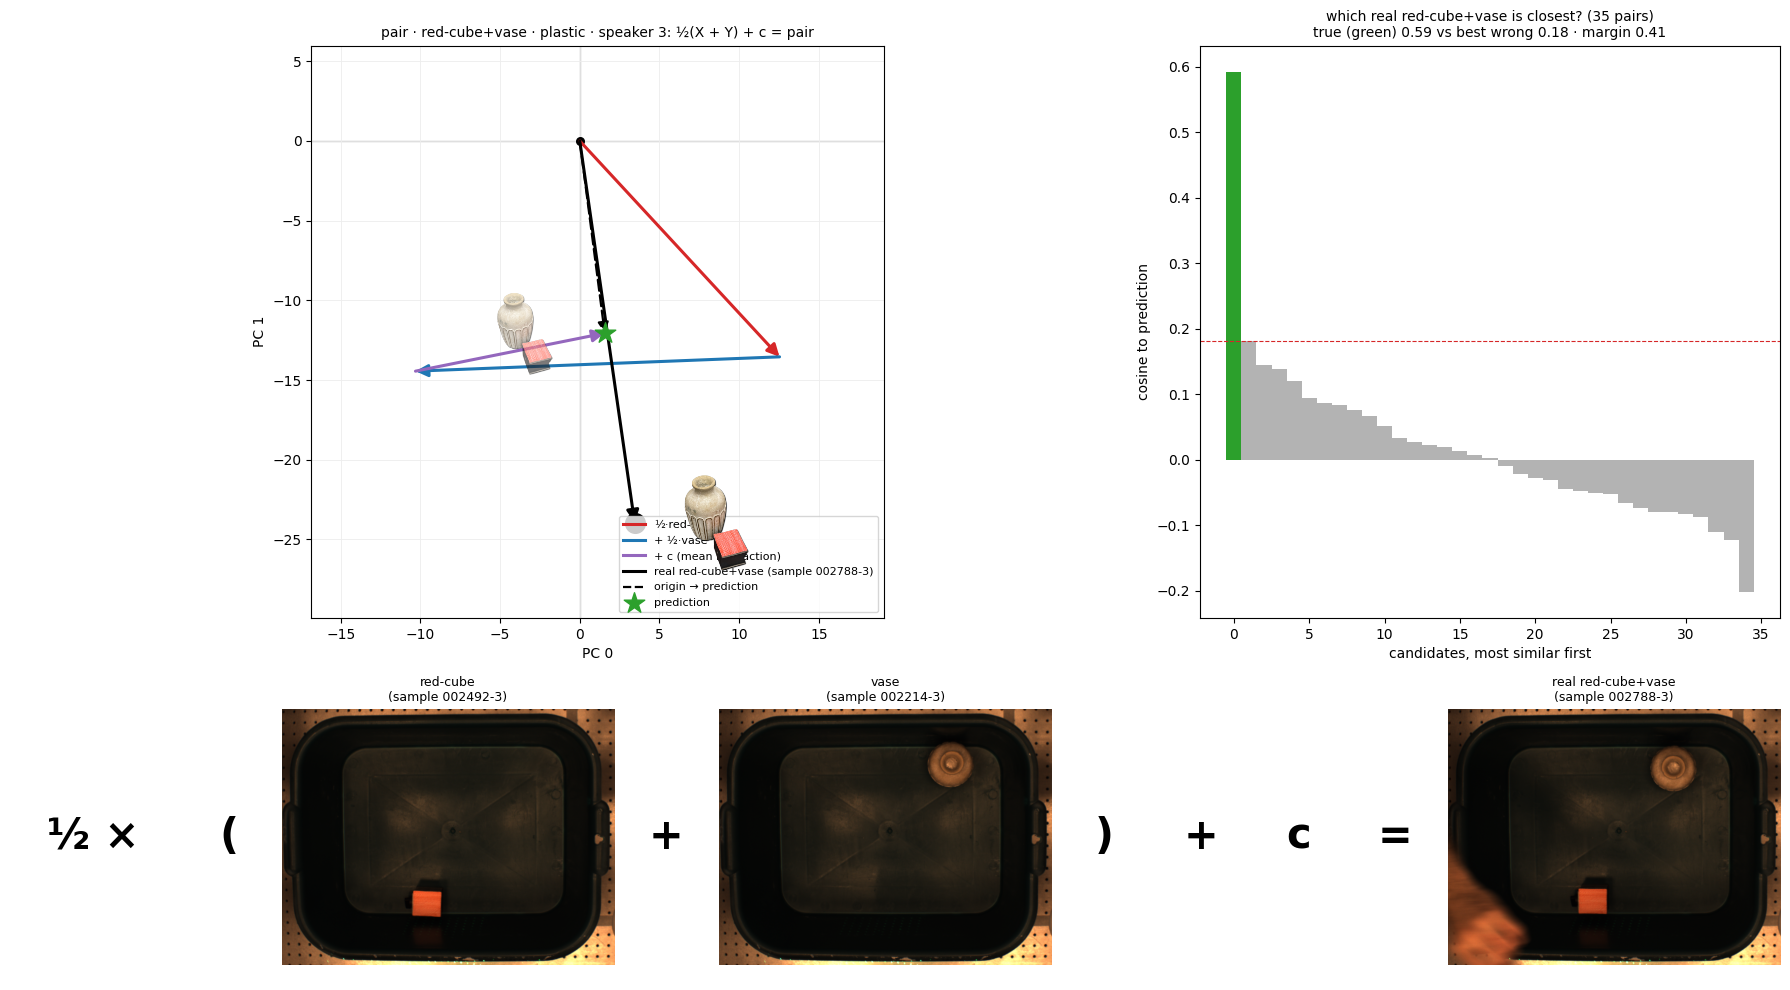

#2 Pandas(Index=9, pair='red-cube+vase', box='plastic', speaker='5', n=35, top1=0.9714285714285714, chance=0.02857142857142857)


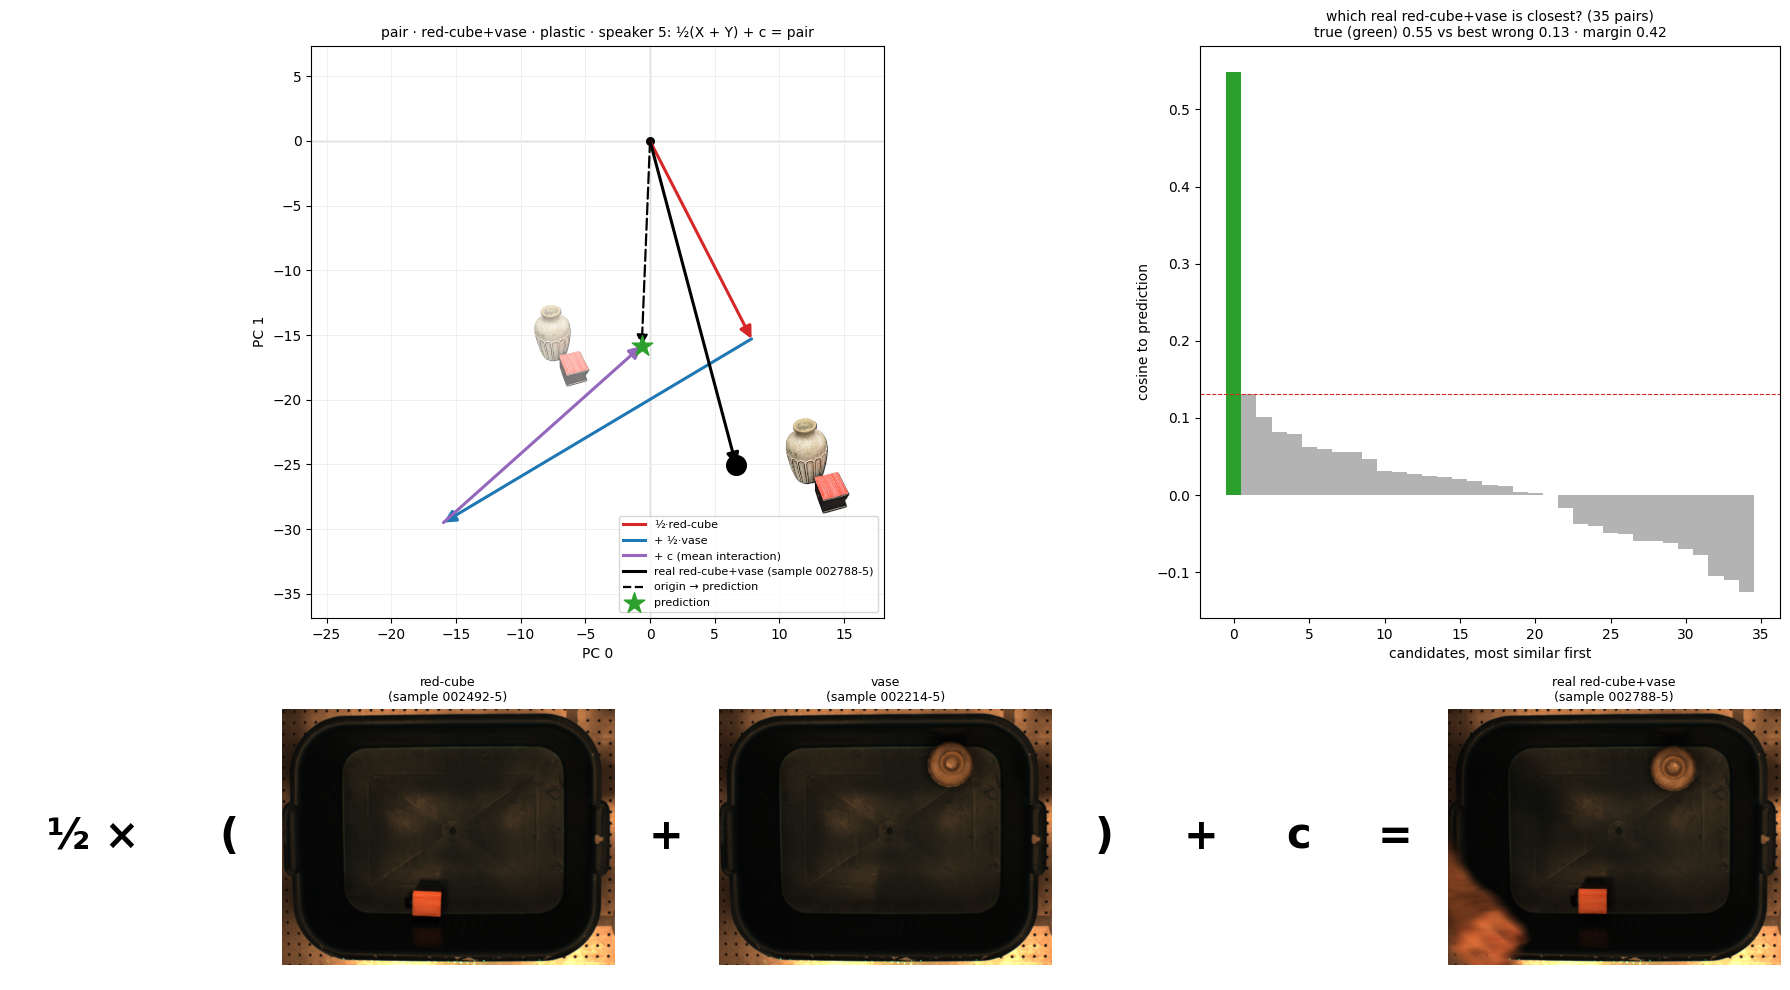

#3 Pandas(Index=10, pair='red-cube+vase', box='plastic', speaker='7', n=35, top1=0.9714285714285714, chance=0.02857142857142857)


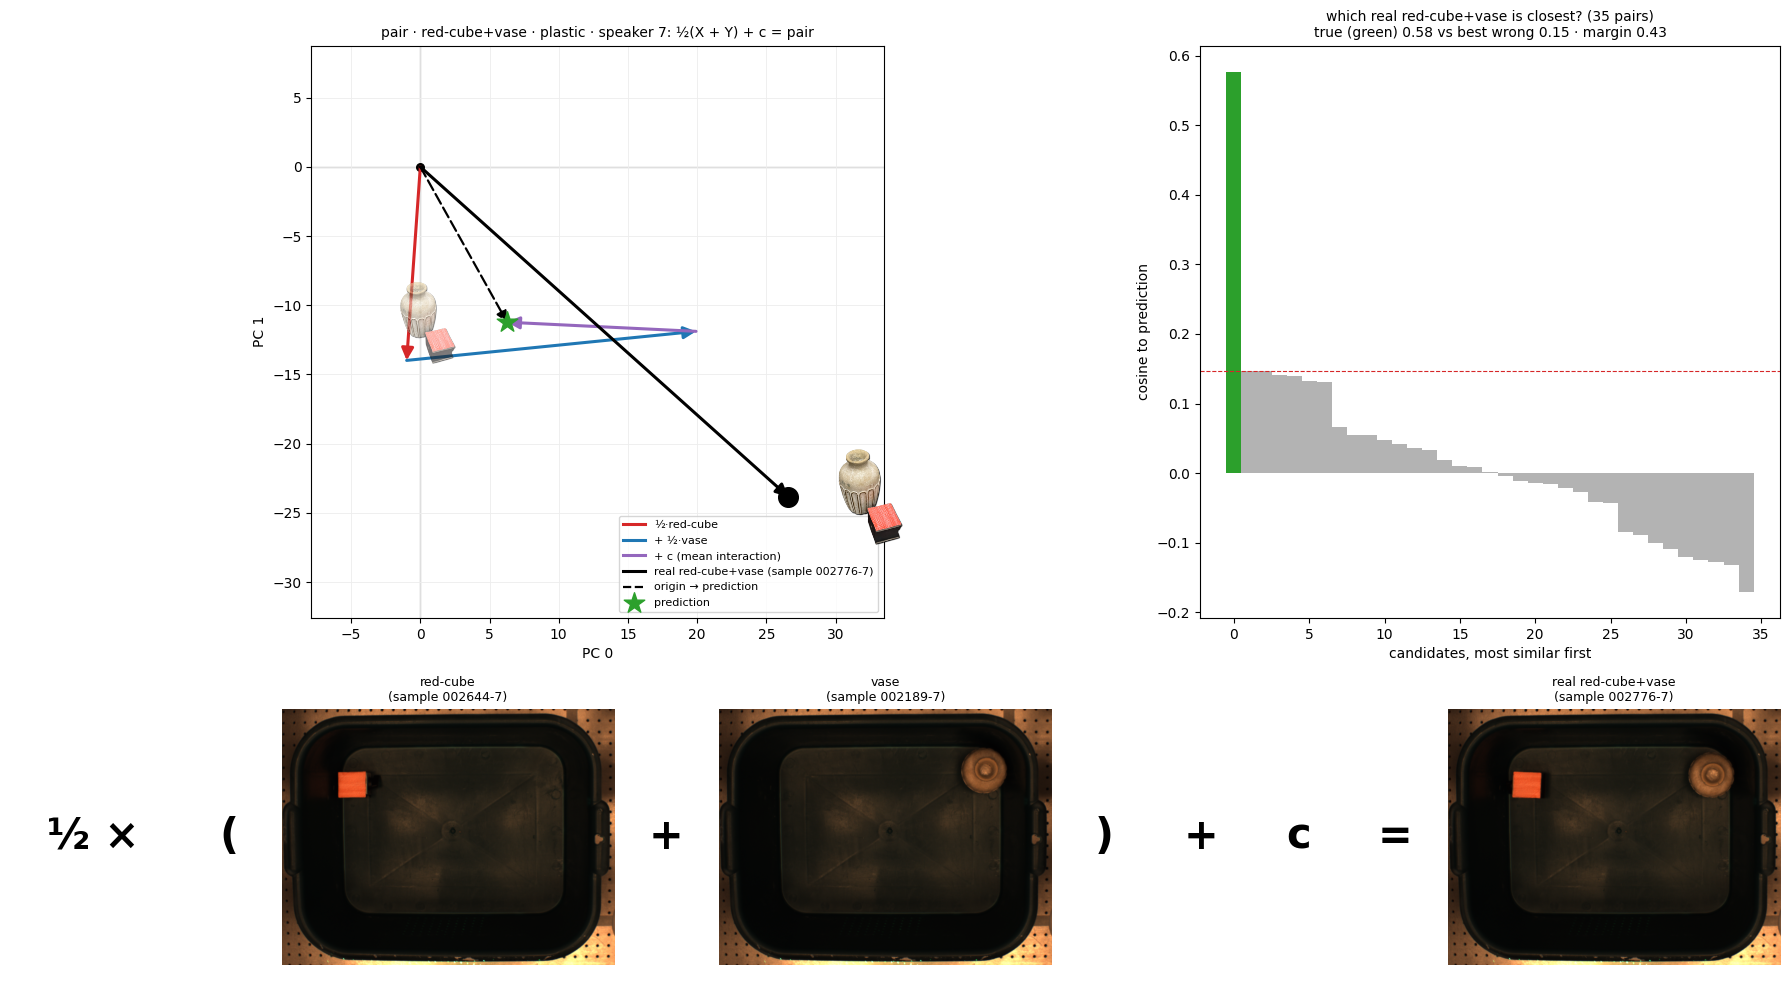

In [10]:
# 1) pair — top 3
for k, r in enumerate(T1.head(TOP).itertuples()): print(f"#{k + 1}", r); figure(EX1[(r.pair, r.box, r.speaker)], f"139_pair_{k + 1}")

#1 Pandas(Index=122, box='plastic', speaker='7', X='red-cube', Y='vase', n=202, top1=0.7821782178217822, chance=0.010979315753357515)


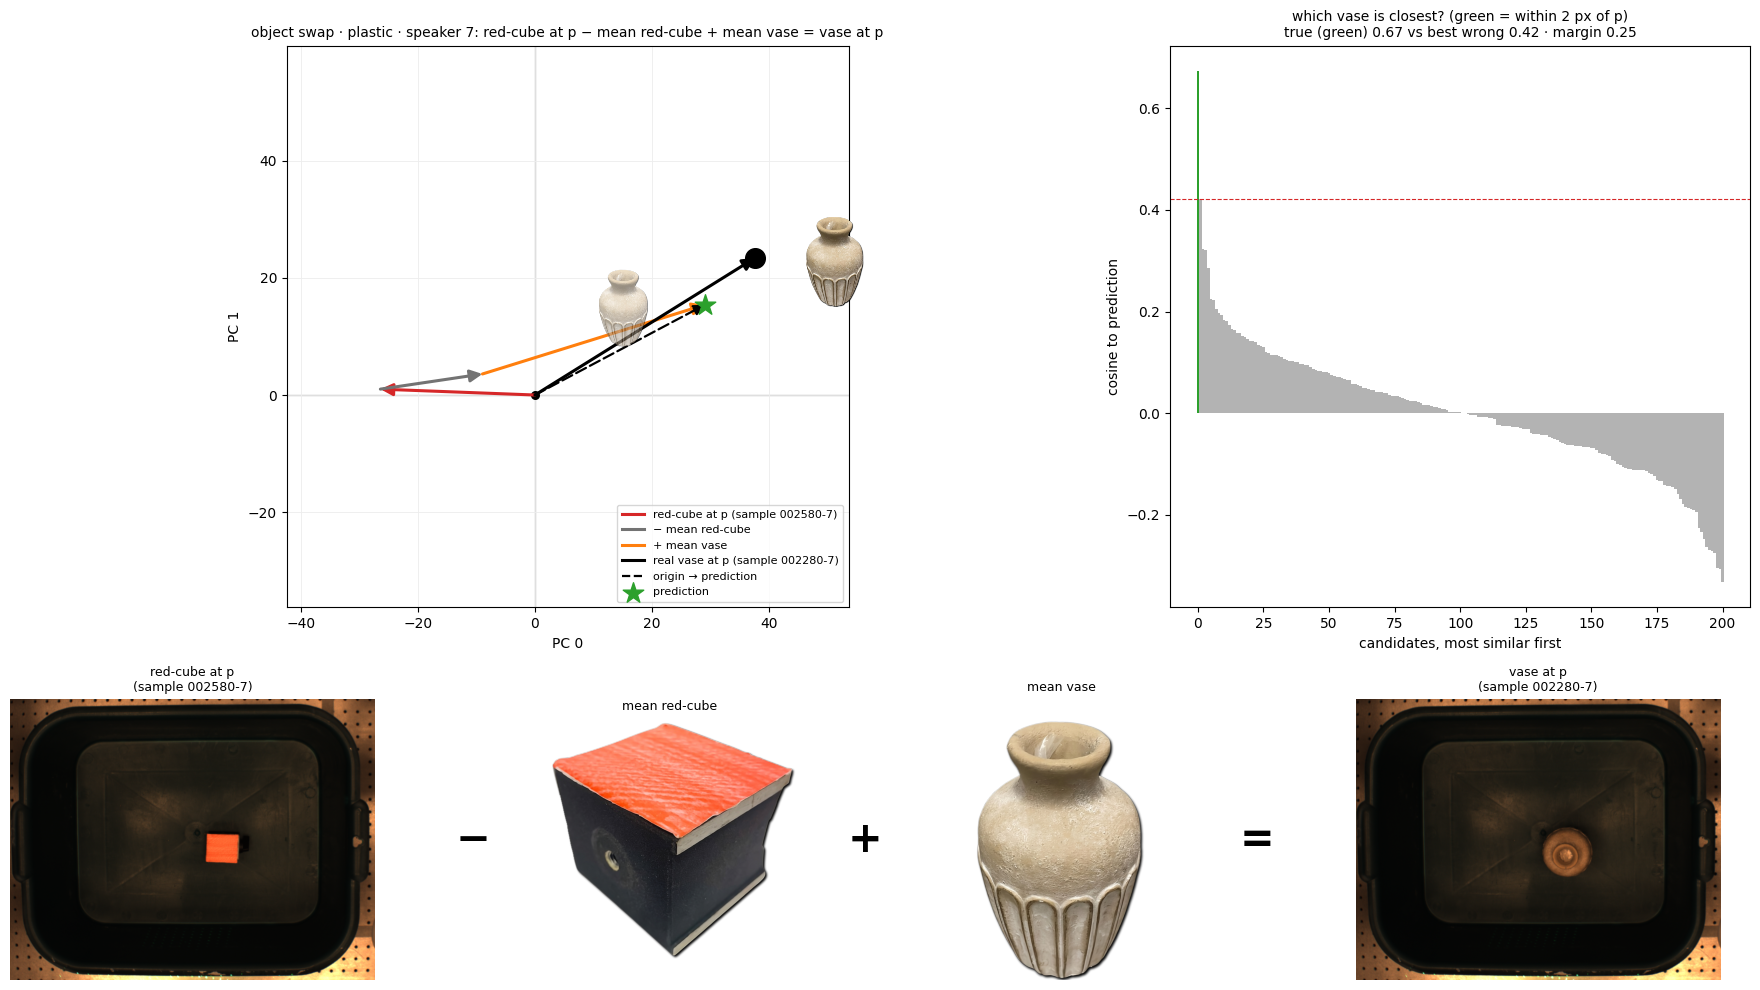

#2 Pandas(Index=98, box='plastic', speaker='3', X='red-cube', Y='vase', n=202, top1=0.7623762376237624, chance=0.01097400380432132)


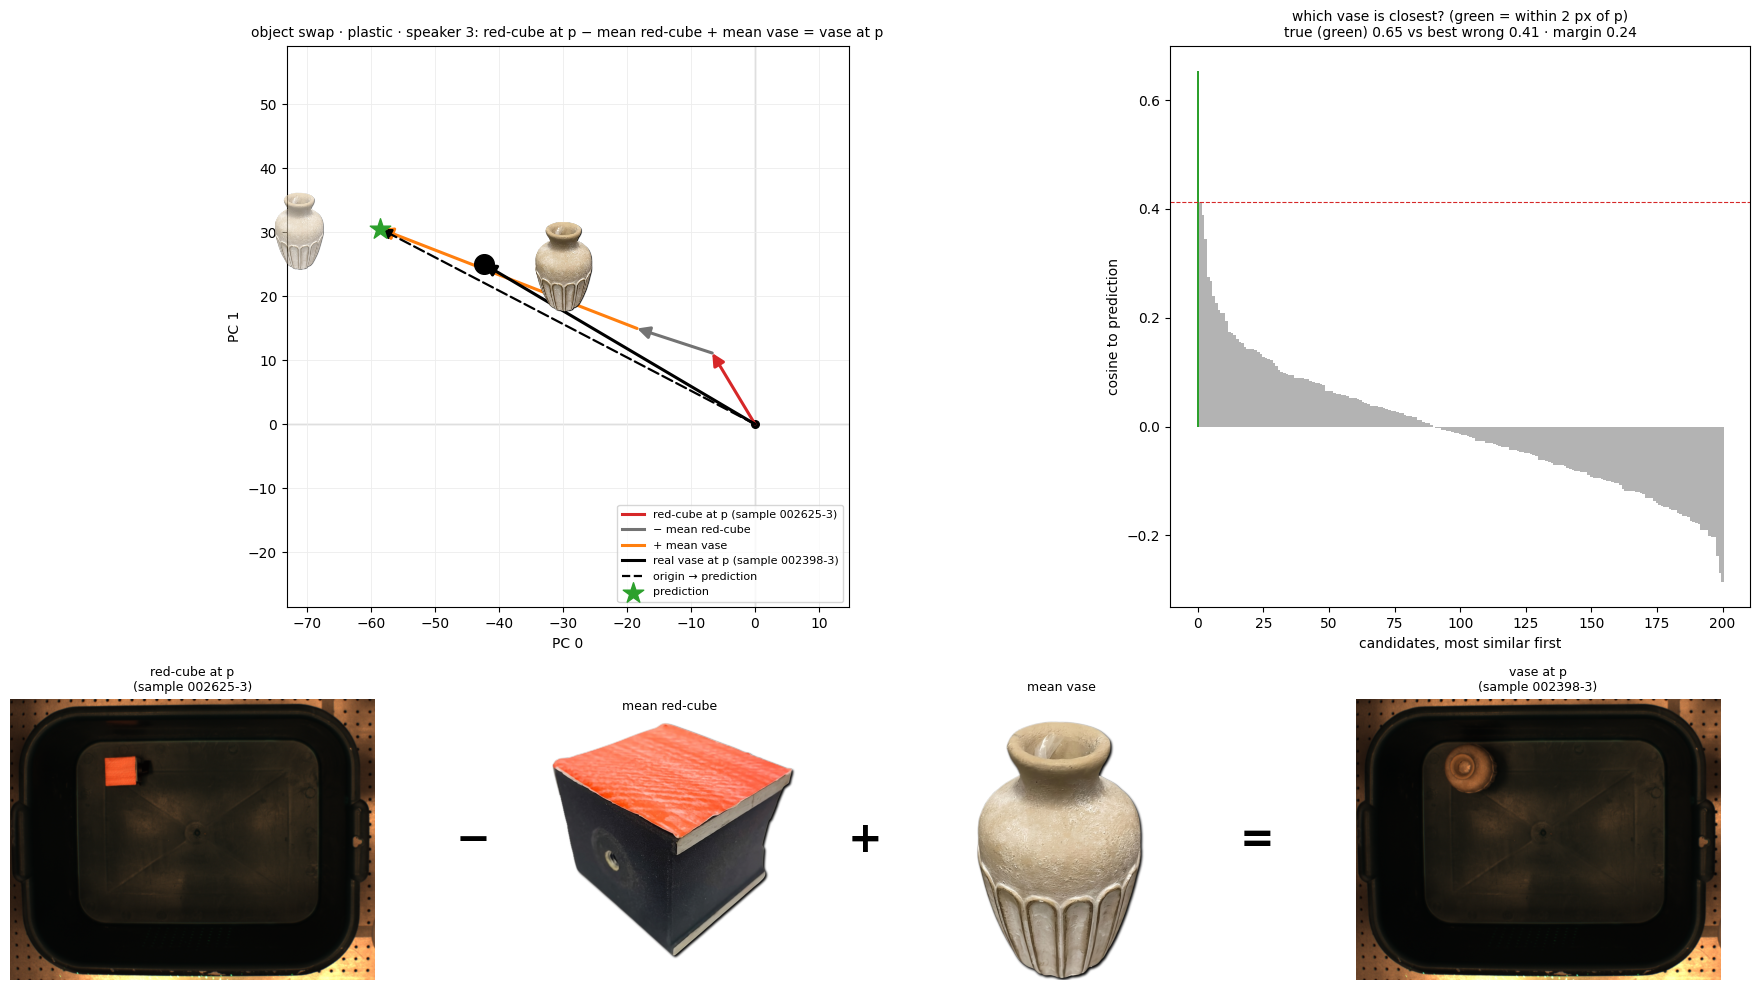

#3 Pandas(Index=86, box='plastic', speaker='1', X='red-cube', Y='vase', n=199, top1=0.7537688442211056, chance=0.0111252781319533)


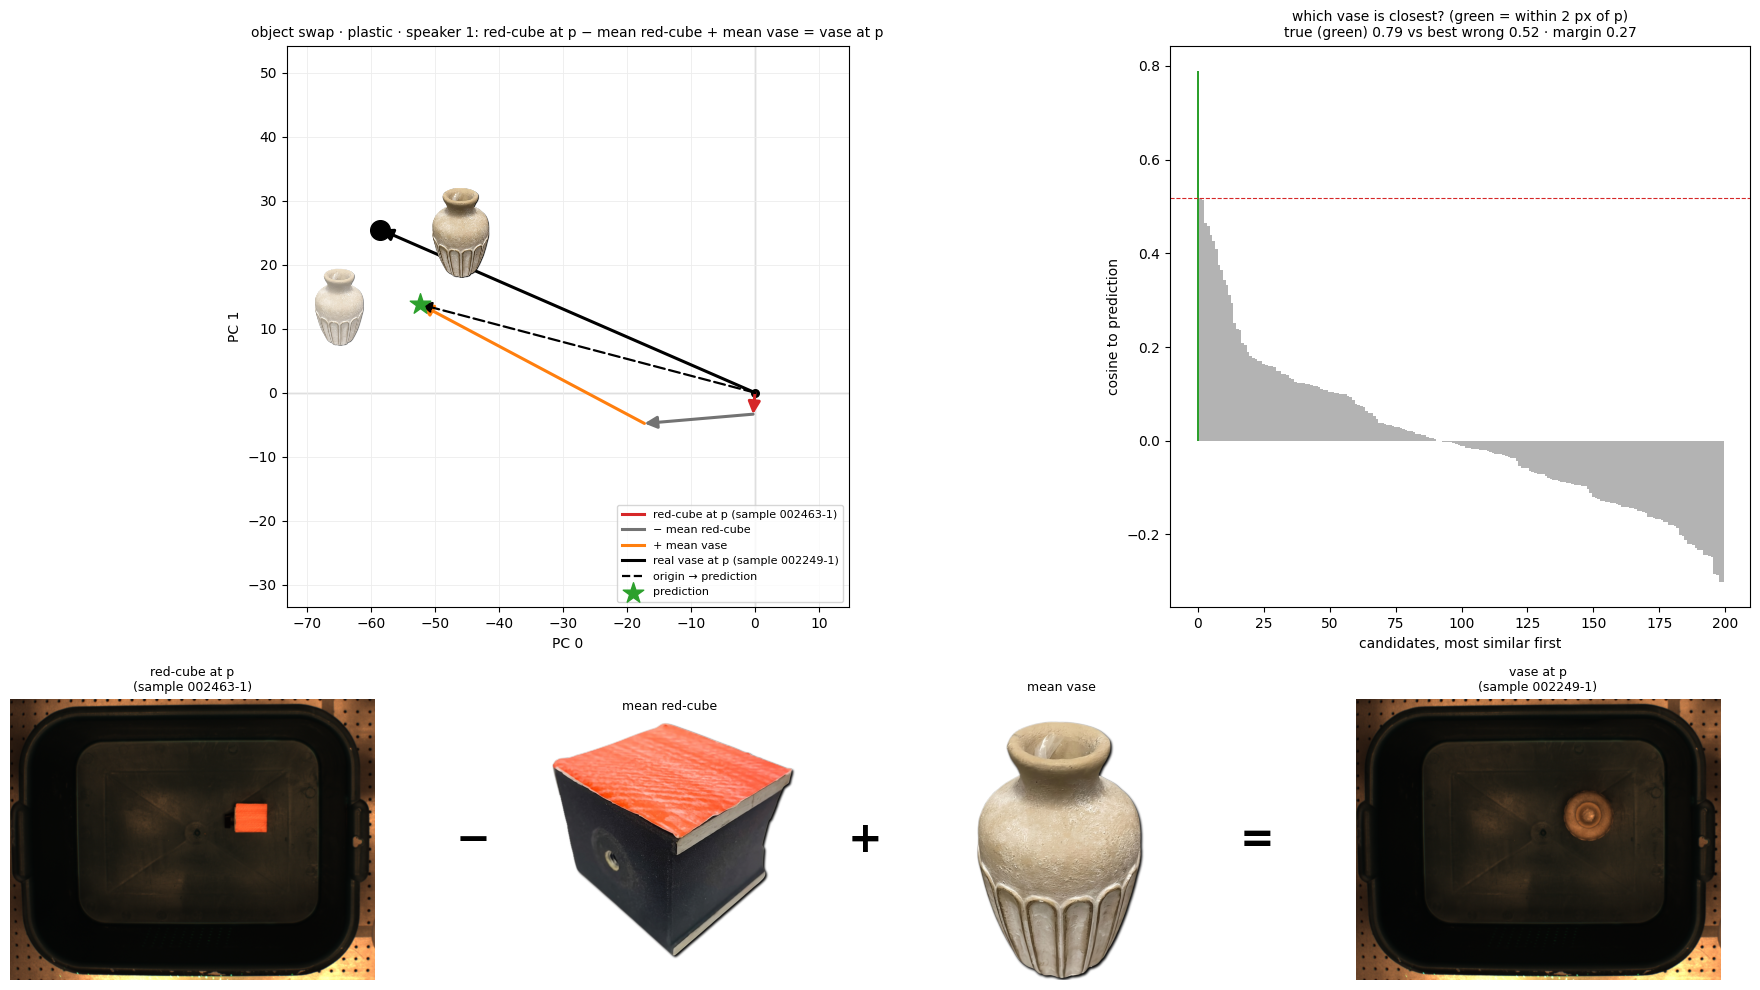

In [11]:
# 2) object swap — top 3
for k, r in enumerate(T2.head(TOP).itertuples()): print(f"#{k + 1}", r); figure(EX2[(r.box, r.speaker, r.X, r.Y)], f"139_swap_{k + 1}")

#1 Pandas(Index=39, speaker='3', object='candle', A='gastro', B='plastic', n=210, top1=0.11904761904761904, chance=0.01111111111111111)


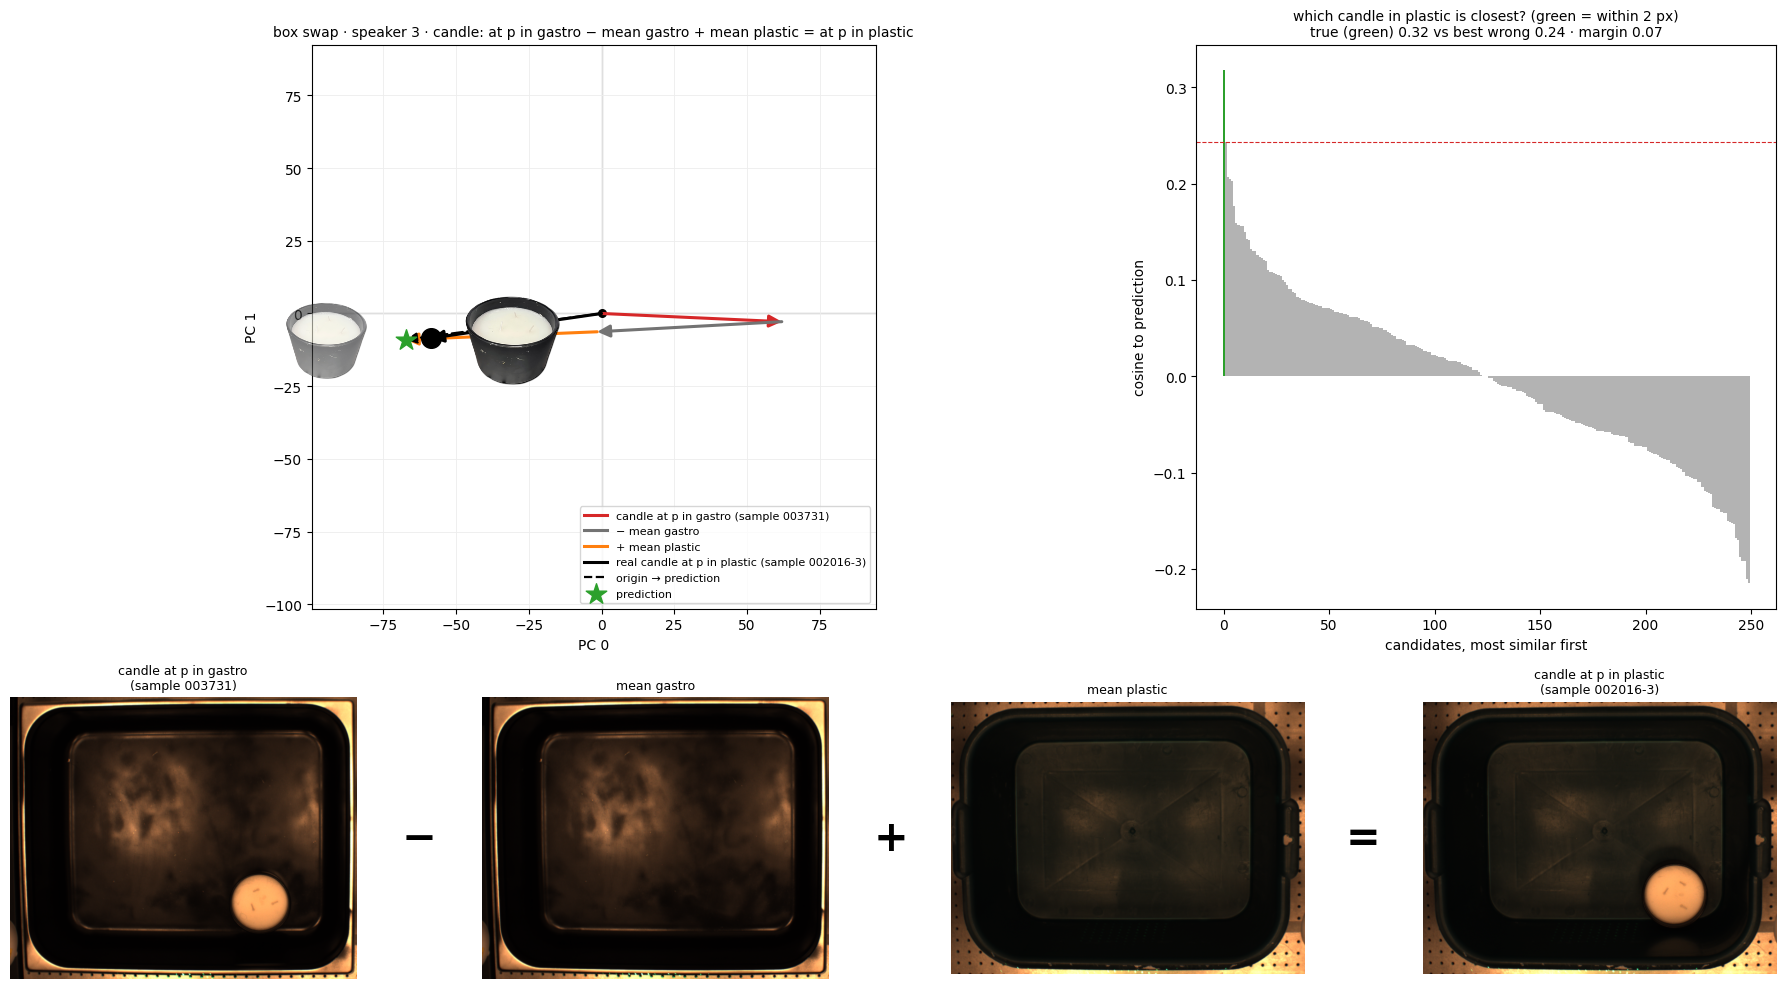

#2 Pandas(Index=44, speaker='3', object='vase', A='gastro', B='cardboard', n=181, top1=0.11049723756906077, chance=0.00887090498793868)


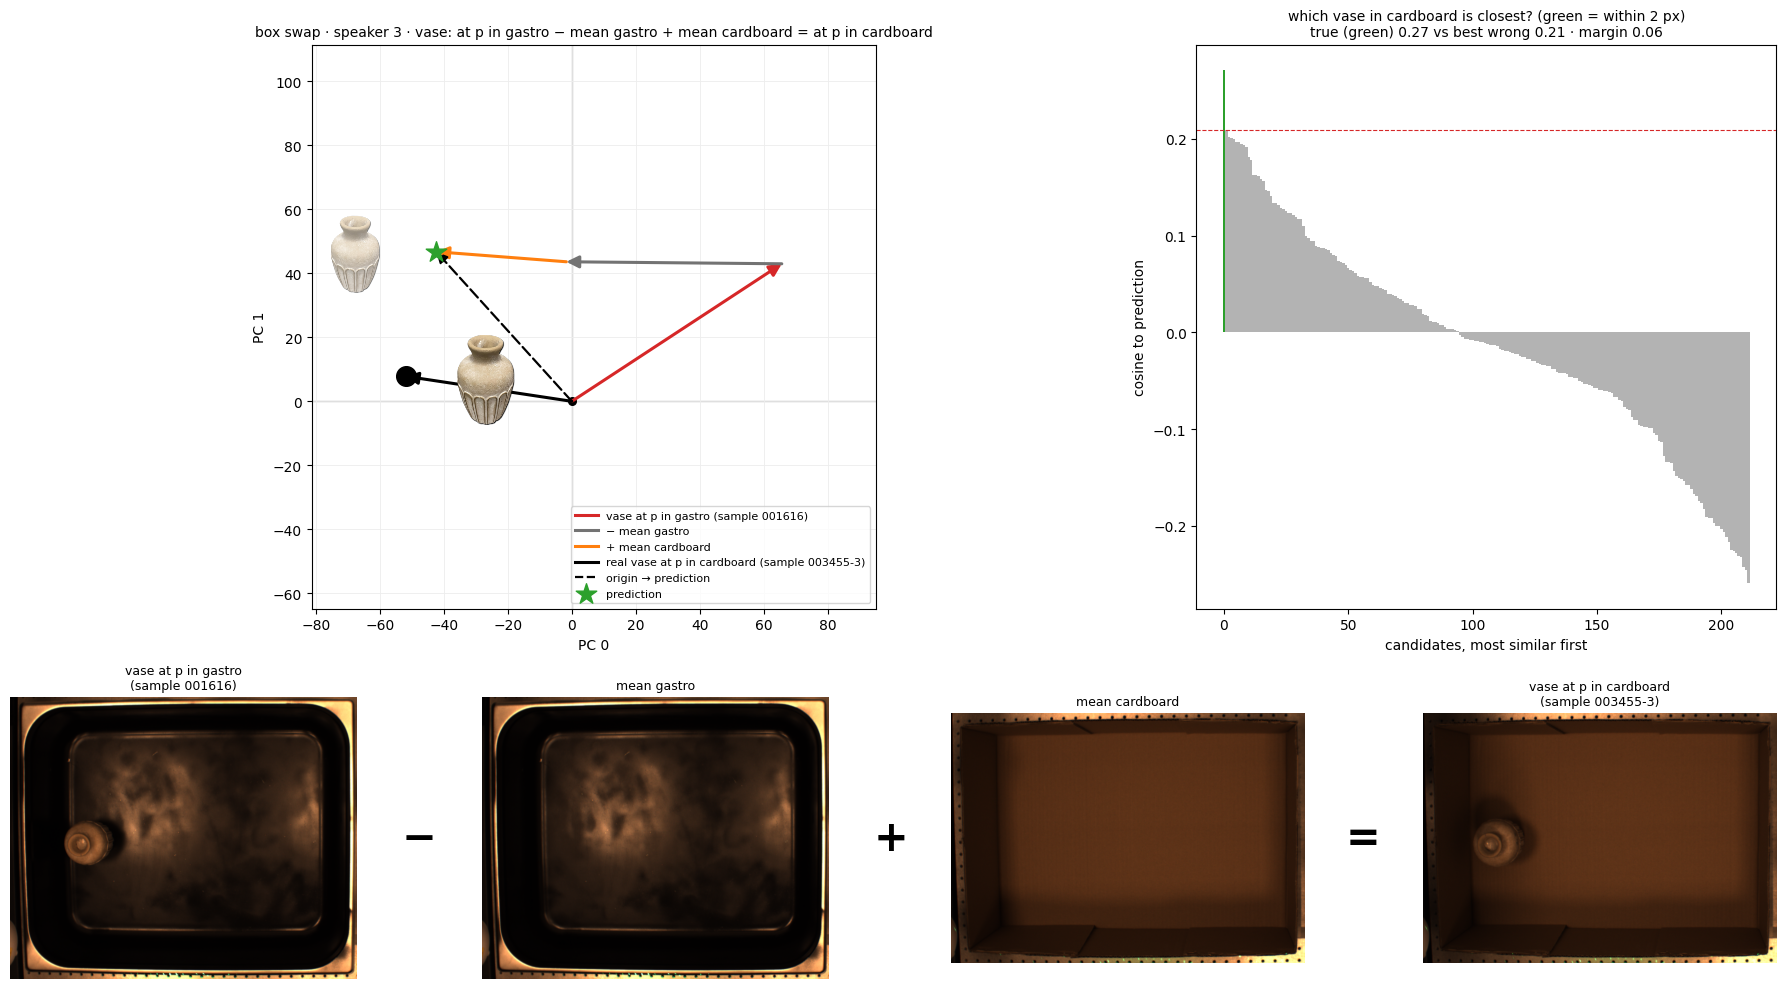

#3 Pandas(Index=73, speaker='7', object='candle', A='plastic', B='gastro', n=245, top1=0.11020408163265306, chance=0.00934065934065934)


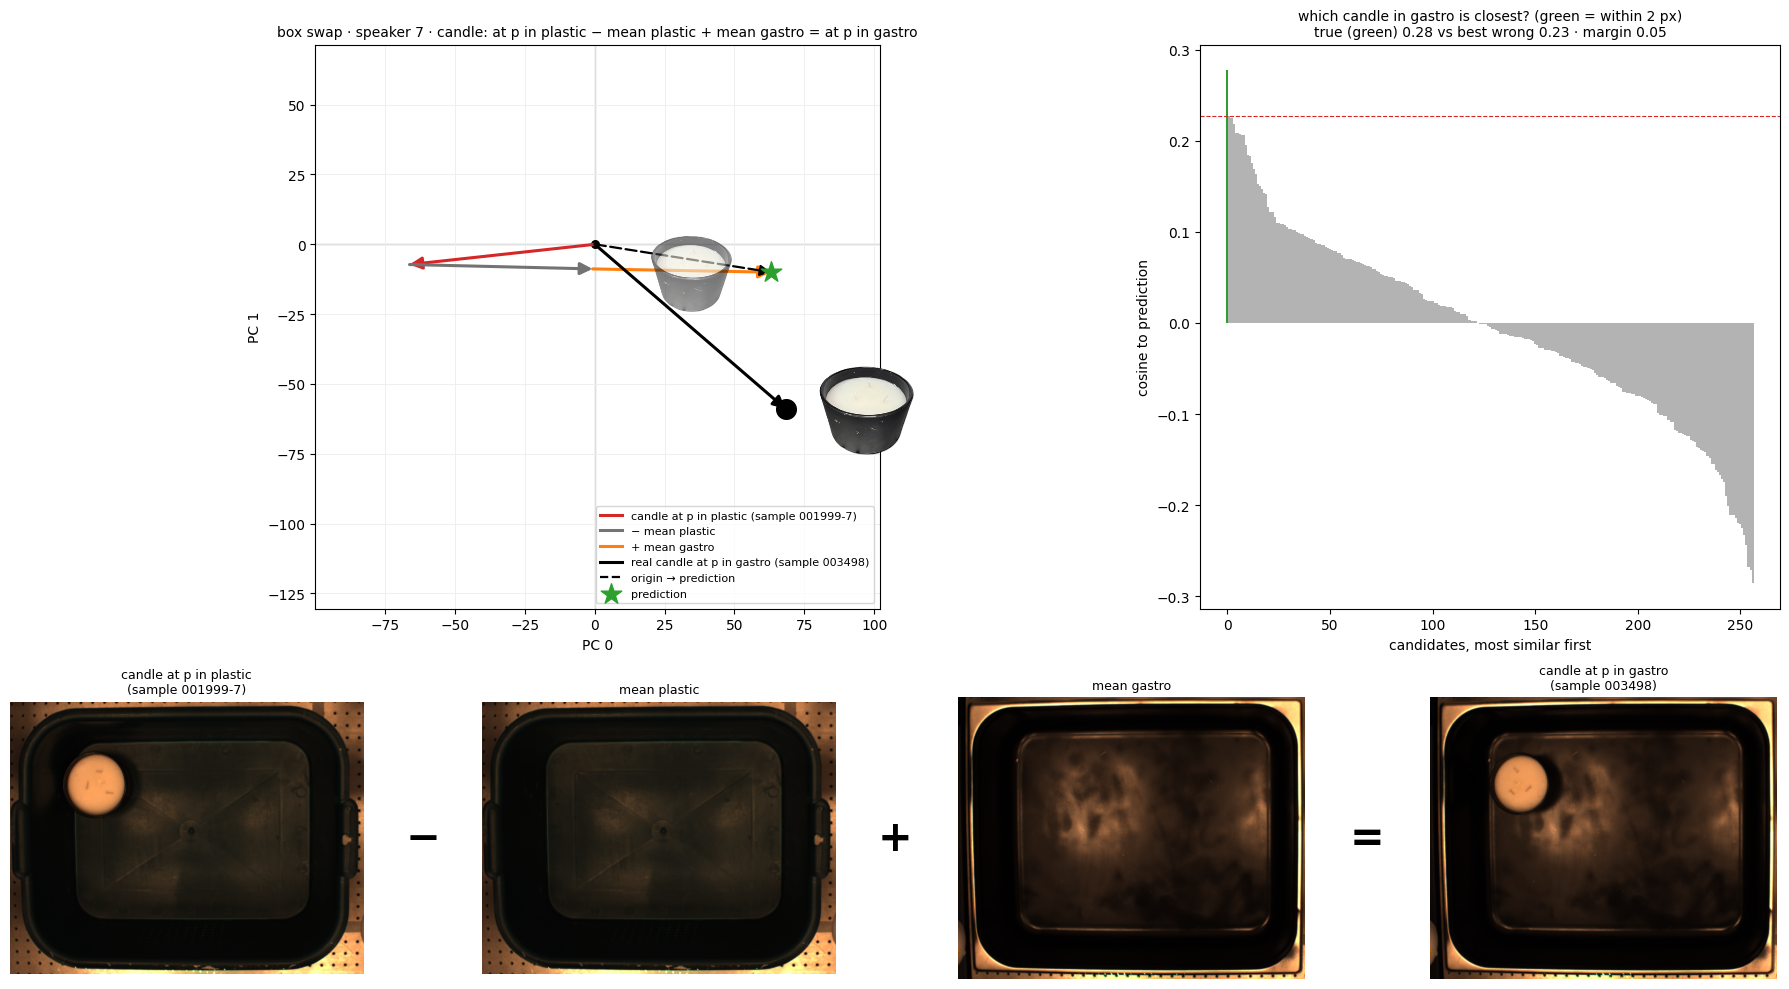

In [12]:
# 3) box swap — top 3
for k, r in enumerate(T3.head(TOP).itertuples()): print(f"#{k + 1}", r); figure(EX3[(r.speaker, r.object, r.A, r.B)], f"139_boxswap_{k + 1}")

#1 Pandas(Index=59, speaker='7', object='red-cube', A='gastro', B='plastic', n=238, top1=0.7184873949579832, chance=0.010704281712685072)


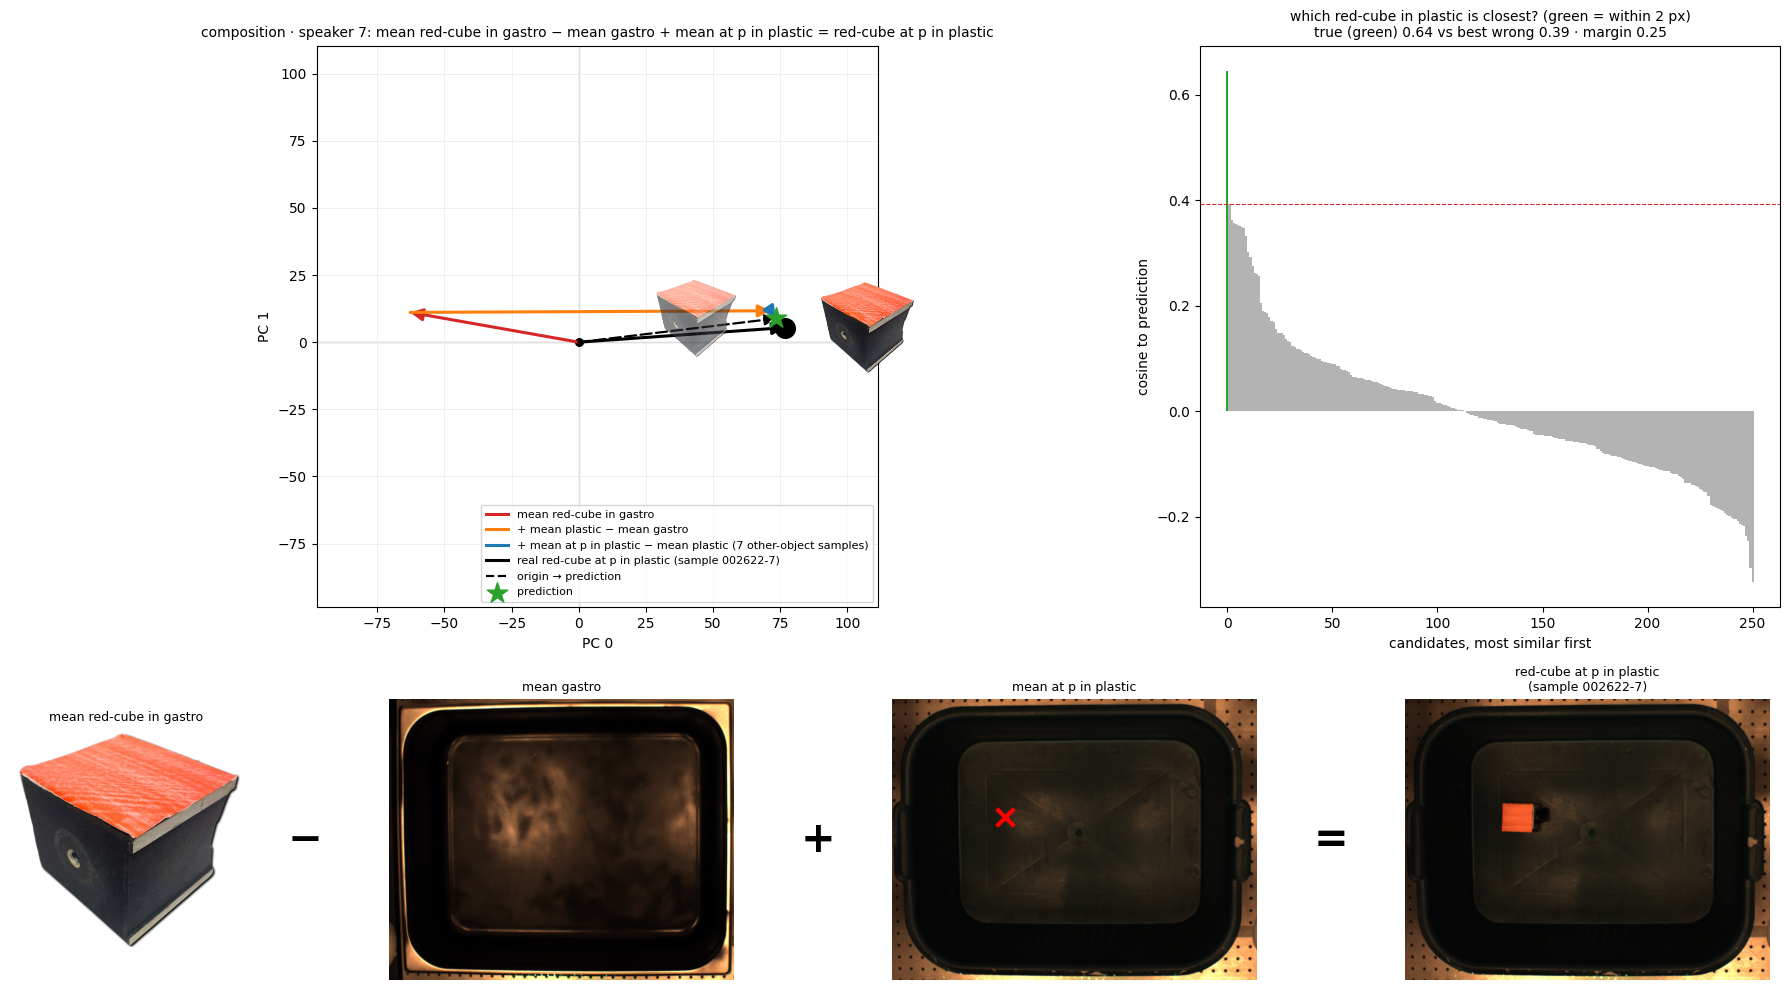

#2 Pandas(Index=57, speaker='7', object='red-cube', A='cardboard', B='plastic', n=238, top1=0.6890756302521008, chance=0.010704281712685072)


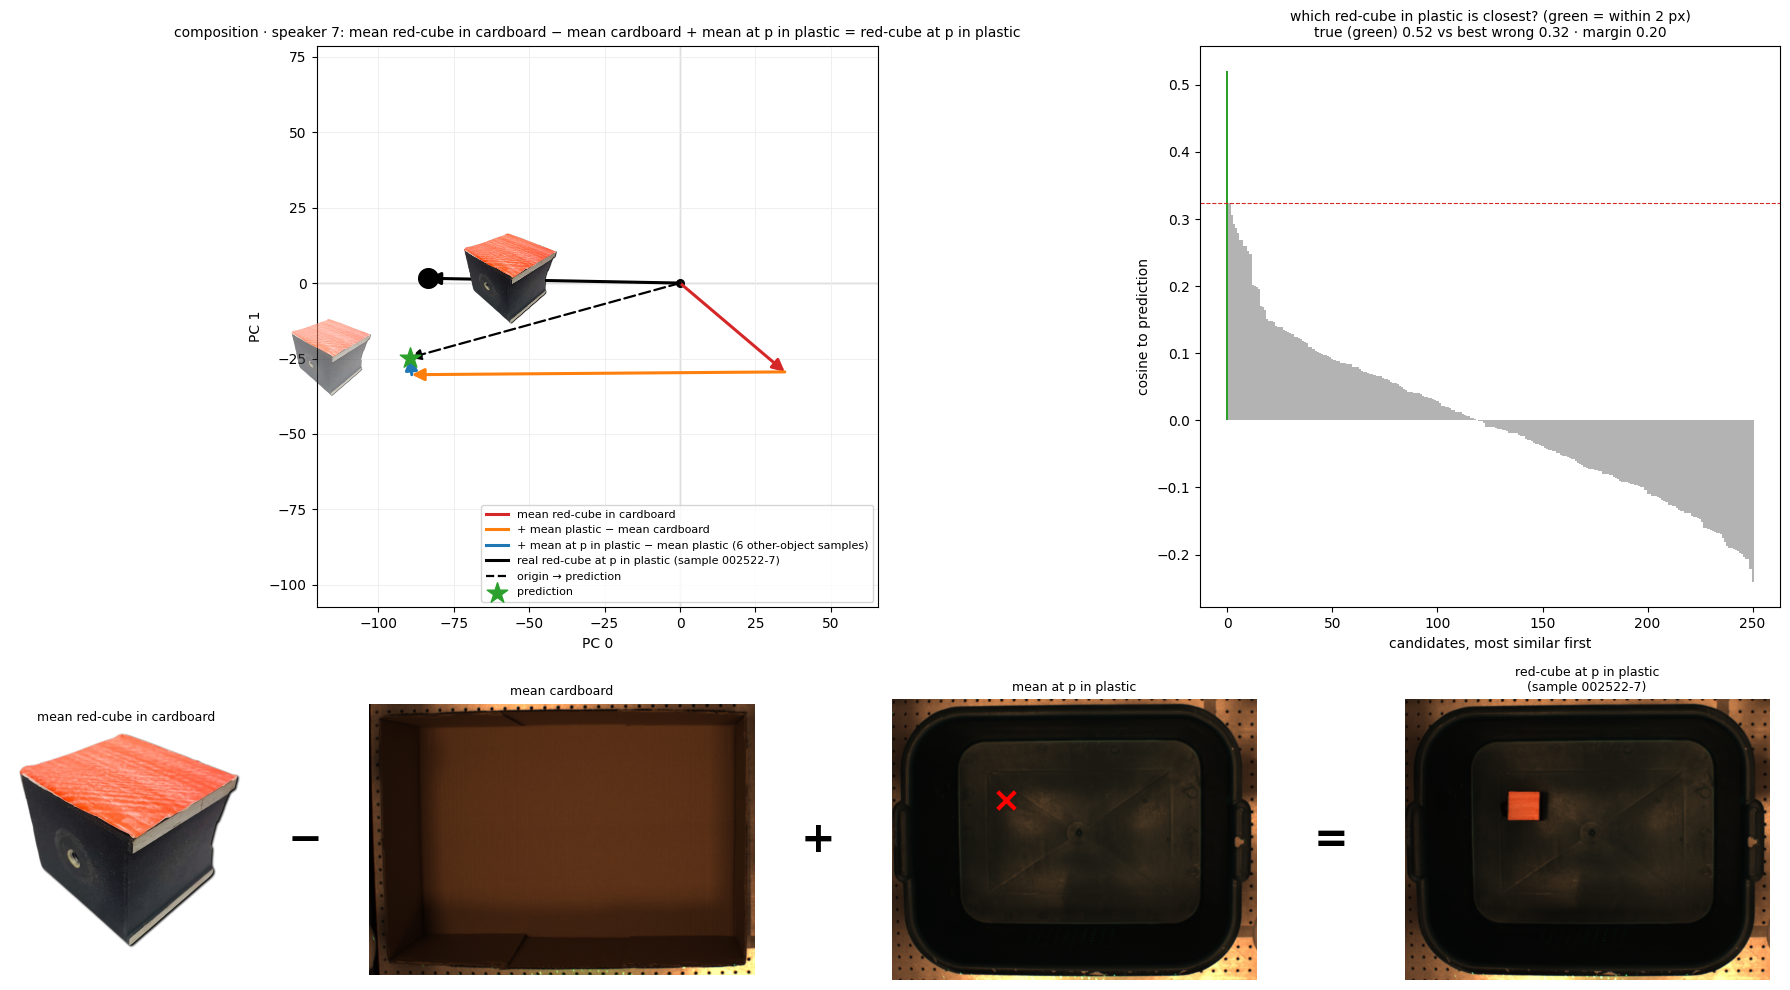

#3 Pandas(Index=3, speaker='1', object='red-cube', A='gastro', B='plastic', n=236, top1=0.6779661016949152, chance=0.010753595786346139)


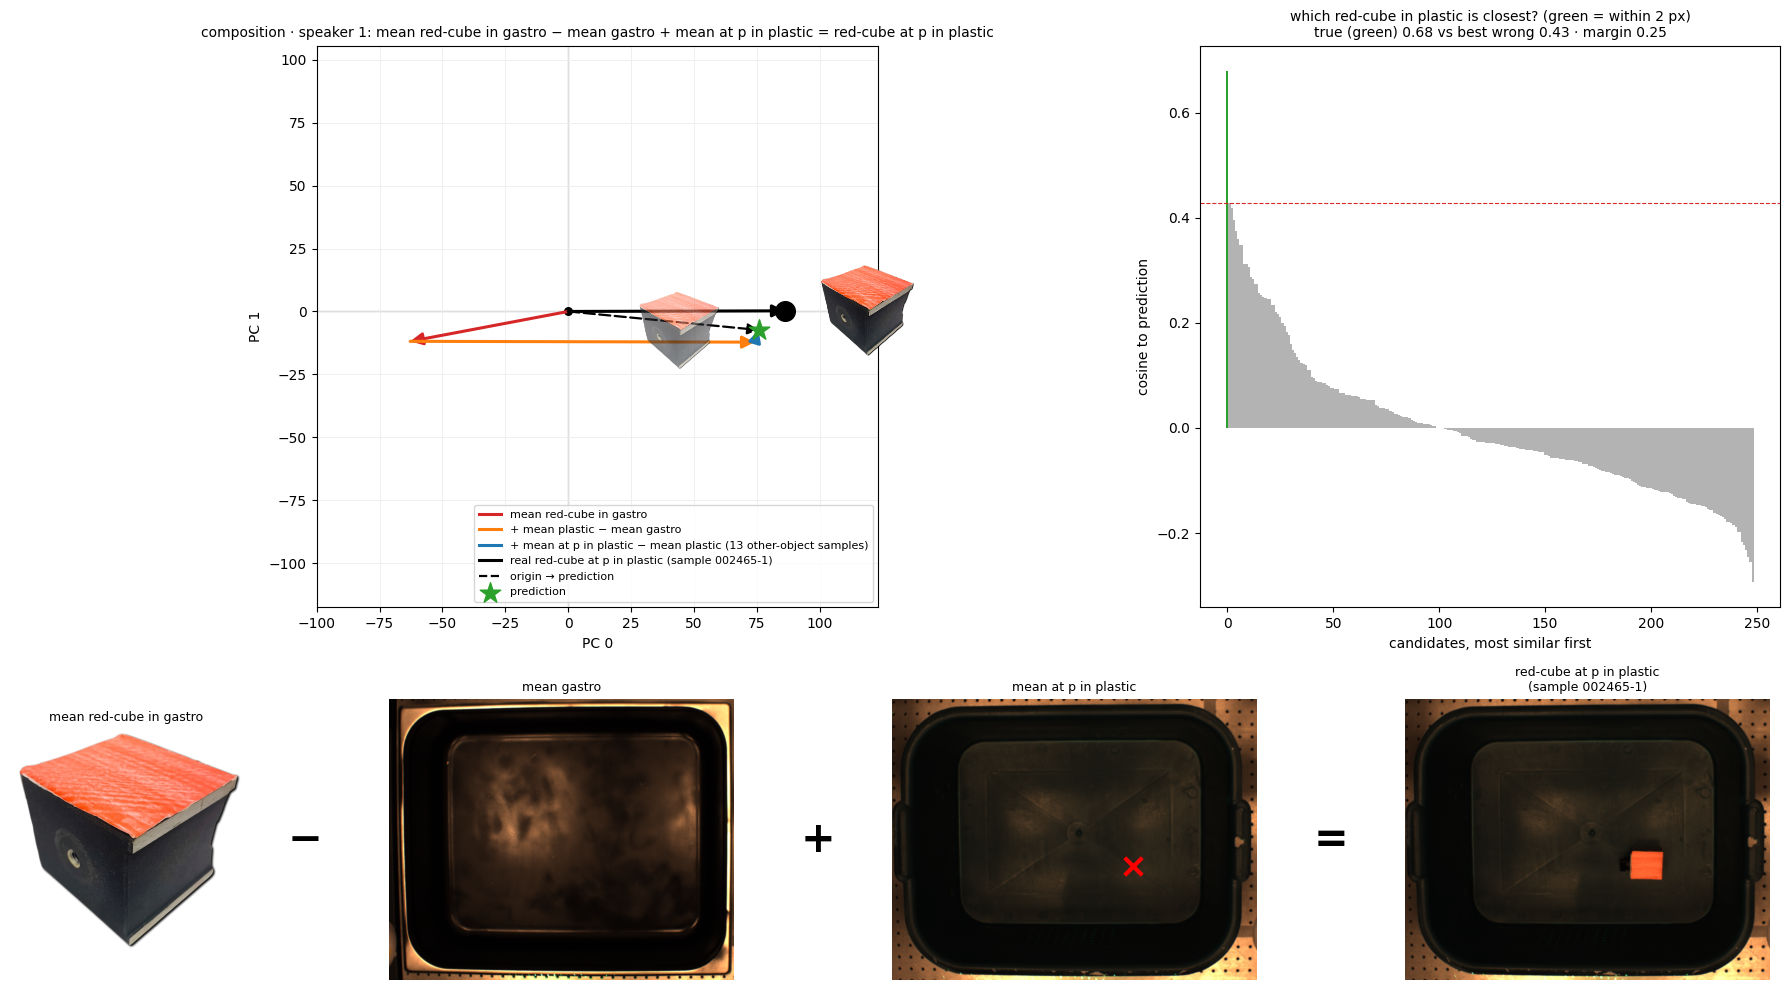

In [13]:
# 4) composition — top 3
for k, r in enumerate(T4.head(TOP).itertuples()): print(f"#{k + 1}", r); figure(EX4[(r.speaker, r.object, r.A, r.B)], f"139_compose_{k + 1}")

#1 Pandas(Index=43, speaker='7', object='vase', box='plastic', n=197, top1=0.751269035532995, chance=0.011835955169120975)


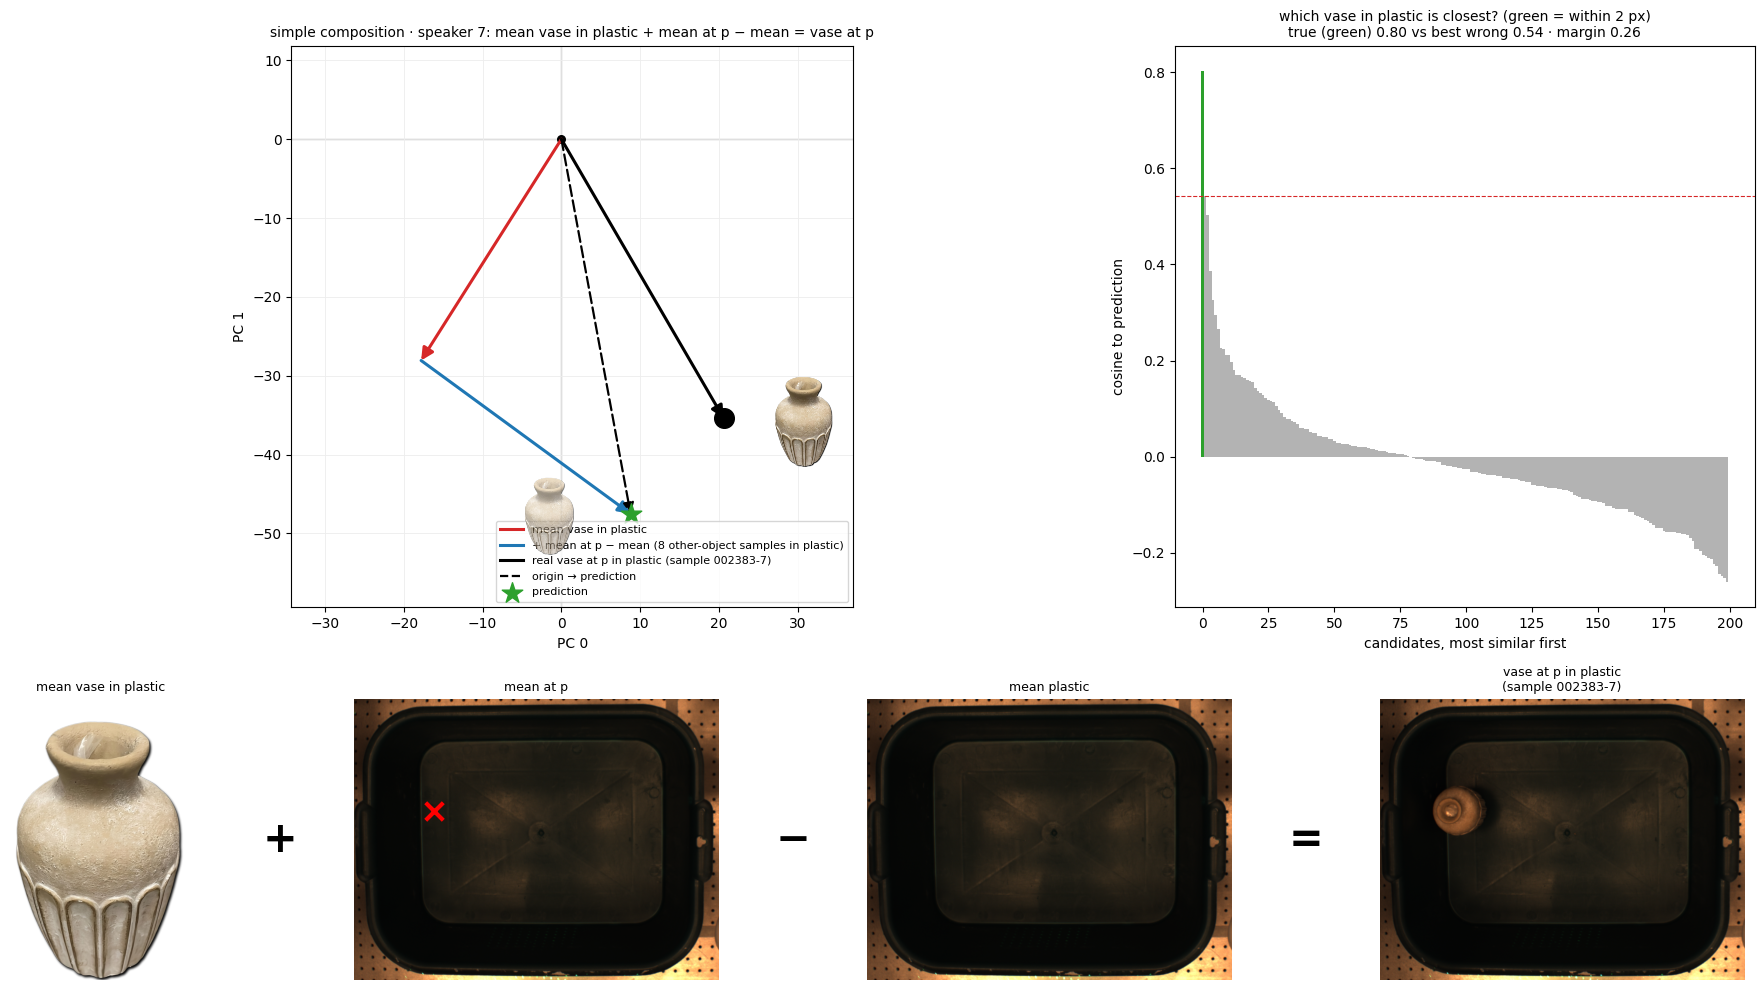

#2 Pandas(Index=8, speaker='1', object='red-cube', box='plastic', n=236, top1=0.7288135593220338, chance=0.010753595786346139)


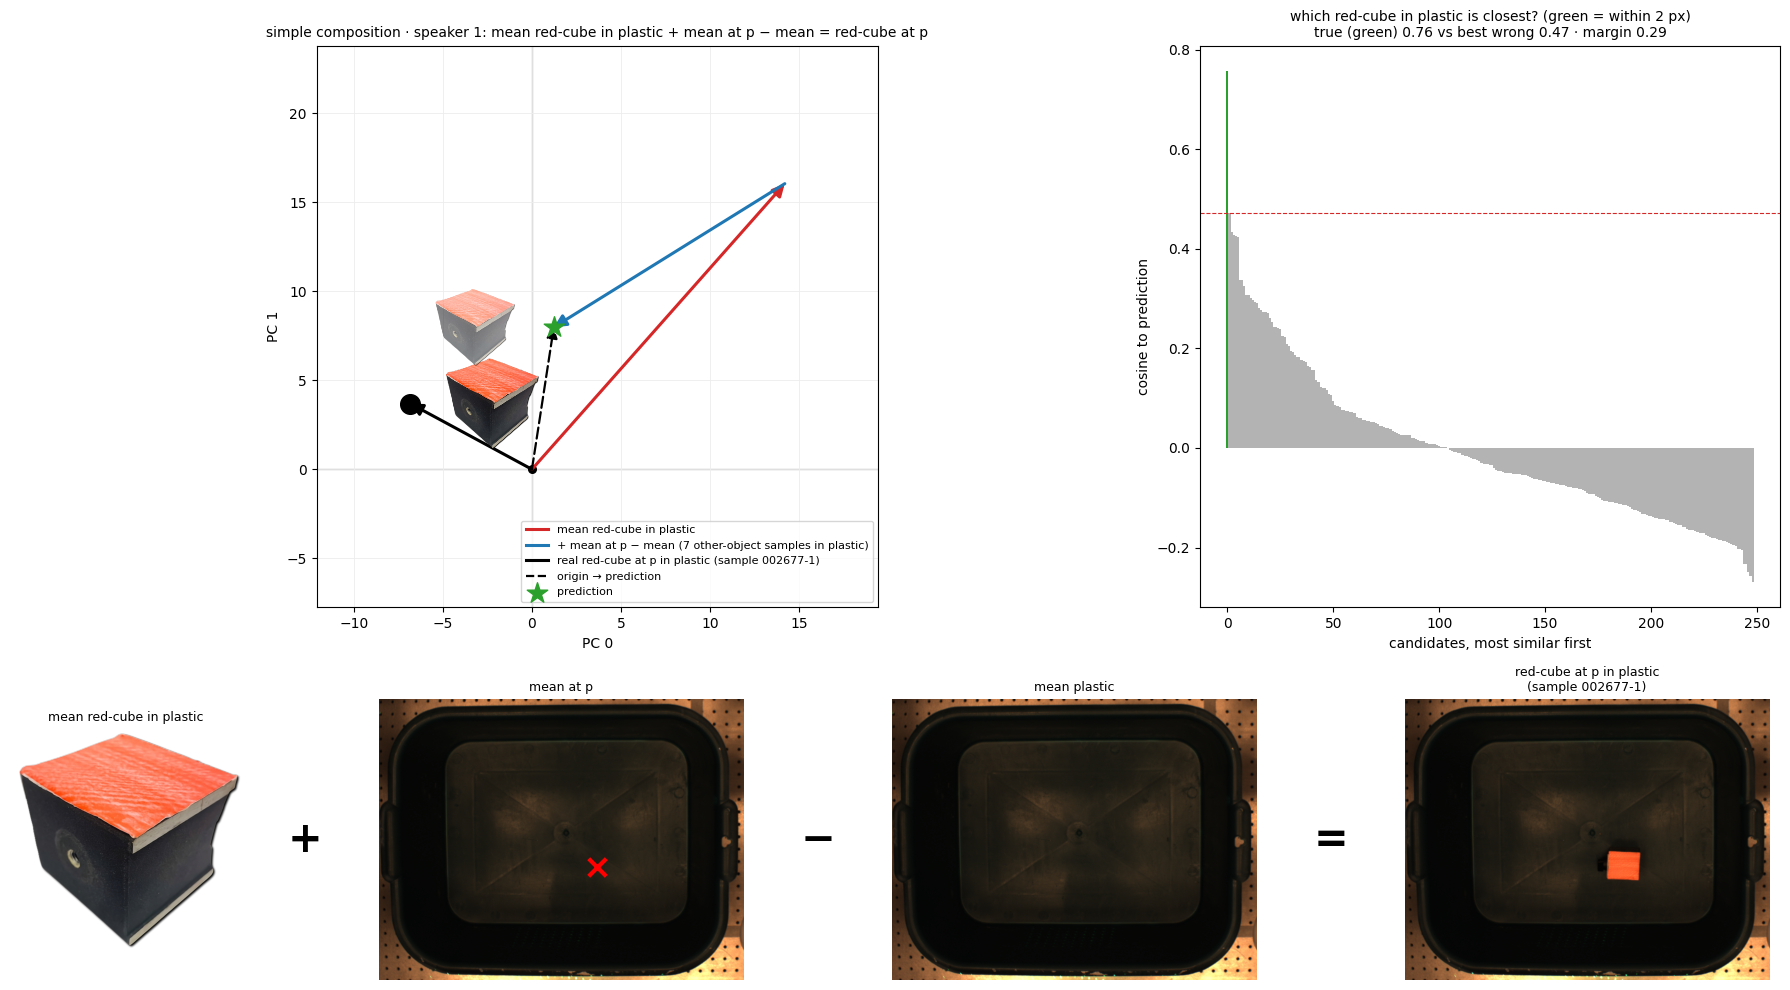

#3 Pandas(Index=40, speaker='7', object='red-cube', box='plastic', n=238, top1=0.7226890756302521, chance=0.010704281712685072)


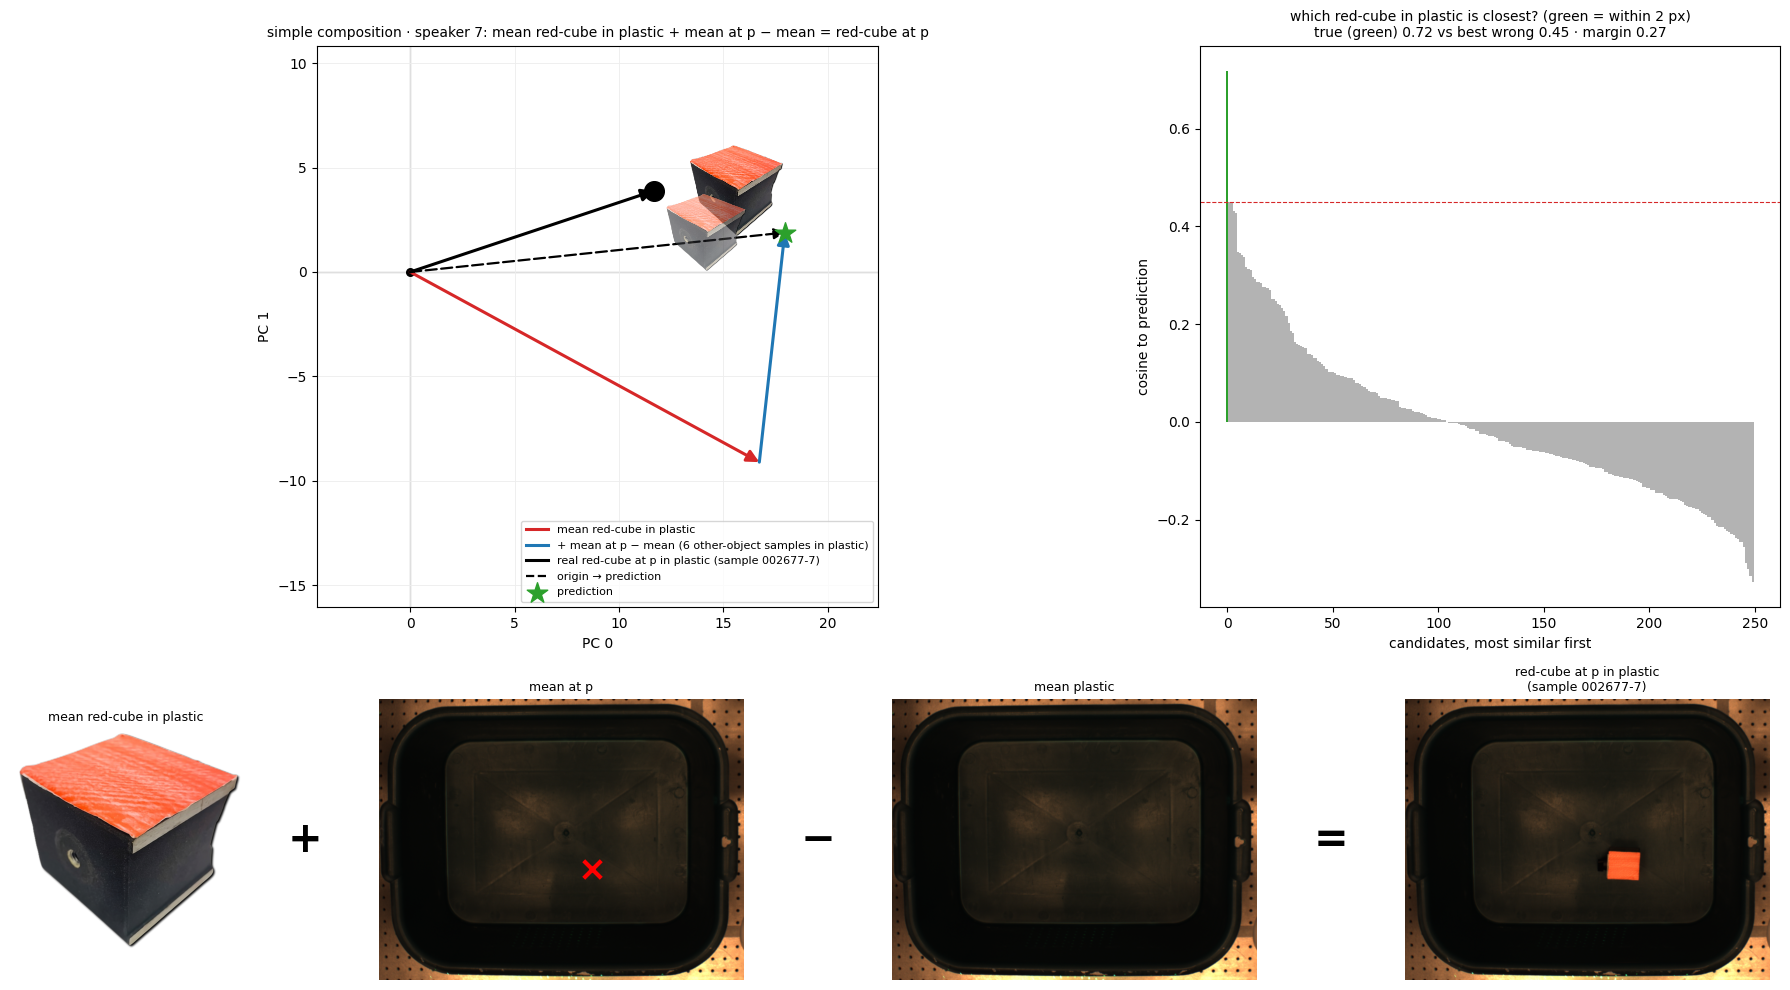

In [14]:
# 4b) simple composition — top 3
for k, r in enumerate(T4b.head(TOP).itertuples()): print(f"#{k + 1}", r); figure(EX4b[(r.speaker, r.object, r.box)], f"139_compose_simple_{k + 1}")